# Boussinesq: CNO vs AWFNO, optional FNO — **real test-set images and physical H¹**

**Visual diagnostics only. NO training or optimizer updates.** Uses the completed native CNO checkpoint and original AWFNO checkpoint at **Ntrain=200, seed=1234**, evaluating the same 70 original test trajectories. Optionally loads the original direct full-trajectory FNO checkpoint.

### What this resolves
A low global absolute L² error does **not** guarantee faithful sharp transported structures. Compare on **exactly the same sample and time**, with **identical temperature colour scales** and **identical absolute-error colour scales**:
1. Ground truth / AWFNO / CNO / optional FNO temperature fields at five times, in physical annulus coordinates;
2. Absolute error panels beneath those same times;
3. Full and final **physical annulus H¹**, separated into L² and gradient-seminorm terms;
4. H¹-versus-time, gradient energy retention, angular high-frequency energy recovery, and paired per-trajectory scatterplots.

Test cases selected **descriptively**, not for model selection: CNO best, median, and worst **final L²** among the 70 sealed-test trajectories. Do not use these images to tune/retrain models without redesignating a new untouched test set.

The output goes to a **new** folder: `MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200`. Existing checkpoints are **read-only** and never overwritten.

**H¹ definition:** \(\|e\|_{H^1(\Omega)}^2 = \int_\Omega (|e|^2+|\partial_r e|^2+r^{-2}|\partial_\theta e|^2)\,r\,dr\,d\theta\). Centered periodic differences in \(\theta\), second-order differences in \(r\), same radial trapezoid and periodic angular quadrature as original absolute L². Relative H¹ is divided by the true field's H¹ at that time.

If a checkpoint is missing/ambiguous, the notebook **stops** rather than plotting an untrained model.

In [1]:
#@title 1. Mount Drive, configure checkpoint-only analysis
from google.colab import drive
from pathlib import Path
import os,sys,subprocess,time,hashlib,urllib.request,importlib,glob,json
import numpy as np
import torch
drive.mount('/content/gdrive')
assert torch.cuda.is_available(), 'Set runtime to GPU (required by this notebook).'
DATASET=Path('/content/gdrive/MyDrive/anus/hyteg_annulus_c_grid_64x128_samples500.pt')
ROOT=Path('/content/gdrive/MyDrive/anus/Boussinesq_JCP')
NATIVE=ROOT/'native_reference_2d'
OUT=ROOT/'CNO_AWFNO_H1_visual_comparison_N200'
OUT.mkdir(parents=True,exist_ok=True)
N_TRAIN=200 #@param {type:'integer'}
SEED=1234 #@param {type:'integer'}
INCLUDE_FNO=True #@param {type:'boolean'}
EVAL_BATCH=4 #@param {type:'integer'}
# Optional explicit checkpoint paths, only if automatic discovery reports ambiguity:
CNO_OVERRIDE='' #@param {type:'string'}
AWFNO_OVERRIDE='' #@param {type:'string'}
FNO_OVERRIDE='' #@param {type:'string'}
assert N_TRAIN in (25,50,100,200,400) and EVAL_BATCH>=1
assert DATASET.is_file(), f'Missing dataset: {DATASET}'
os.environ.update({'DATA_PATH':str(DATASET),'OUTPUT_ROOT':str(ROOT),
                   'SPLIT_MODE':'contiguous','TIME_SUBSAMPLE':'1',
                   'N_VAL':'30','N_TEST':'70','RUN_SAMPLE_SIZES':'25,50,100,200,400',
                   'SEED':str(SEED),'WINDOW_K':'30','WINDOW_STRIDE':'30',
                   'N_TIME_MODES':'18','WIDTH':'32','N_LAYERS':'4',
                   'MODES_R':'16','MODES_THETA':'24','LOCAL_RADIUS':'2',
                   'FINAL_LOSS_WEIGHT':'0','ENFORCE_MEAN':'0',
                   'NATIVE_OUTPUT':str(NATIVE)})
print('GPU:',torch.cuda.get_device_name(0))
print('Dataset:',DATASET)
print('Existing checkpoint root:',ROOT)
print('New visualization-only outputs:',OUT)


Mounted at /content/gdrive
GPU: Tesla T4
Dataset: /content/gdrive/MyDrive/anus/hyteg_annulus_c_grid_64x128_samples500.pt
Existing checkpoint root: /content/gdrive/MyDrive/anus/Boussinesq_JCP
New visualization-only outputs: /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200


In [2]:
#@title 2. Fetch implementation files (read-only) and initialize geometry
BASE_URL='https://raw.githubusercontent.com/dimigourz/AWFNO/main/Boussinesq2D/'
FILES=('annulus2d_jcp_experiments.py','reference_architectures_2d.py',
       'native_method_baselines_2d.py')
# The original FNO implementation uses the maintained neuralop package.
if INCLUDE_FNO:
    try: from neuralop.models import FNO
    except ImportError:
        subprocess.run([sys.executable,'-m','pip','install','-q',
                        'neuraloperator==2.0.0'],check=True)
for filename in FILES:
    req=urllib.request.Request(BASE_URL+filename+'?cache='+str(time.time_ns()),
                               headers={'Cache-Control':'no-cache'})
    with urllib.request.urlopen(req,timeout=90) as response:
        contents=response.read()
    (Path('/content')/filename).write_bytes(contents)
    print('[SOURCE]',filename,hashlib.sha256(contents).hexdigest(),flush=True)
sys.path.insert(0,'/content')
import annulus2d_jcp_experiments as base
import reference_architectures_2d as architectures
import native_method_baselines_2d as native
assert base.WINDOW_K==30 and base.WINDOW_STRIDE==30
assert base.N_TRAIN_POOL==400 and base.N_VAL==30 and base.N_TEST==70
U_all,r,theta,t,sample_ids=base.load_annulus_dataset(DATASET)
U_all,r,theta=base.downsample_polar_grid(U_all,r,theta,base.TARGET_NR,base.TARGET_NTHETA)
base.set_geometry_from_arrays(U_all.shape,r,theta,t)
pool,train_ids,val,val_ids,test,test_ids=base.make_train_val_test_splits(U_all)
assert tuple(test.shape[1:])==(64,128,101) and len(test)==70
assert np.array_equal(test_ids,np.arange(430,500))
print('[DATASET] same contiguous train/validation/test split as original study')
print('Test IDs:',test_ids[0],'-',test_ids[-1])


[SOURCE] annulus2d_jcp_experiments.py a4d78c78bda2703e408ae90ed501dd56334294c9082c086ab2516df6a7acc883
[SOURCE] reference_architectures_2d.py fb5eb6e417e02441cacec154a4451a63a725d78e5863353ef0a8ac100ecdd4a5
[SOURCE] native_method_baselines_2d.py 4f0b923402239e95cce610fec65d29f6da4a8ab74e47ed18a9ba701a471651ec
Using device: cuda
GPU: Tesla T4

Loaded annulus data
-------------------
file: /content/gdrive/MyDrive/anus/hyteg_annulus_c_grid_64x128_samples500.pt
U                       : shape=(500, 64, 128, 101), dtype=float32, memory=1.541 GB
r shape: (64,)
theta shape: (128,)
t shape: (101,)
U min/max: -0.13059653341770172 1.0094236135482788

Geometry
--------
N, Nr, Ntheta, Nt: 500 64 128 101
r range          : 0.5 1.0
theta range      : 0.0 6.234097957611084
DR               : 0.007936507936507936
DTHETA           : 0.04908738521234052
DT_SNAPSHOT      : 1.0

Data split
----------
split mode       : contiguous
U_train_pool     : (400, 64, 128, 101)
U_val            : (30, 64, 128, 101)

In [3]:
#@title 3. Find best-validation CNO and original AWFNO/FNO checkpoints — do not retrain
from pathlib import Path
def one_file(candidates,label,override=''):
    if override:
        p=Path(override)
        if not p.is_file():raise FileNotFoundError(f'{label}: override does not exist: {p}')
        return p
    found=sorted(set(Path(x) for x in candidates if Path(x).is_file()))
    if len(found)!=1:
        print(f'[{label}] found {len(found)} candidates:')
        for p in found:print('  ',p)
        raise RuntimeError(f'{label}: need exactly one matching checkpoint; '
                           f'fill in {label} override in Cell 1 and rerun.')
    print(f'[CHECKPOINT] {label}:',found[0])
    return found[0]
cno_path=one_file(NATIVE.glob(
    f'runs/CNO/N{N_TRAIN}_seed{SEED}_*/training_checkpoint.pt'),
    'CNO',CNO_OVERRIDE)
aw_path=one_file(ROOT.glob(
    f'cache_annulus2d_awfno_sample_sweep_*/models/N{N_TRAIN}_AWFNO_*.pt'),
    'AWFNO',AWFNO_OVERRIDE)
fno_path=None
if INCLUDE_FNO:
    candidates=list(ROOT.glob(
        f'cache_annulus2d_awfno_sample_sweep_*/models/N{N_TRAIN}_FNO_*.pt'))
    if not candidates and not FNO_OVERRIDE:
        print('[FNO] Original FNO checkpoint not found. Plotting CNO and AWFNO only.')
        INCLUDE_FNO=False
    else:
        fno_path=one_file(candidates,'FNO',FNO_OVERRIDE)

def load_trusted(path):
    # These are trusted checkpoints created by your own experiments.
    return torch.load(path,map_location='cpu',weights_only=False)
ck=load_trusted(cno_path)
assert ck.get('config',{}).get('model')=='CNO'
assert ck['config']['N_train']==N_TRAIN and ck['config']['seed']==SEED
assert ck.get('best_model') is not None,'CNO lacks best-validation model'
cno=architectures.make_native_model('CNO',r,theta).to(base.device)
cno.load_state_dict(ck['best_model'],strict=True)
cno.eval()
cno_norm=native.StateNormalizer(pool[:N_TRAIN])
print('[MODEL] CNO best epoch:',ck.get('best_epoch'),'params:',base.count_params(cno))

aw_ck=load_trusted(aw_path)
assert aw_ck.get('meta',{}).get('n_train')==N_TRAIN,'AWFNO N mismatch'
awfno=base.AWFNO2d(base.WINDOW_K,r,theta).to(base.device)
awfno.load_state_dict(base.clean_state_dict(aw_ck['state_dict']),strict=True)
awfno.eval()
# Reconstruct exactly the original normalization from training windows.
# K=30, stride=30 gives starts 0,30,60 and disjoint target times 1..90.
starts=base.make_window_start_indices(base.Nt,base.WINDOW_K,base.WINDOW_STRIDE)
assert starts==[0,30,60]
source_starts=torch.from_numpy(np.stack([pool[:N_TRAIN,...,s] for s in starts],
                                         axis=0).astype(np.float32))
source_future=torch.from_numpy(np.ascontiguousarray(pool[:N_TRAIN,...,1:91]))
aw_input_norm=base.GaussianNormalizer(source_starts).to(base.device)
aw_future_norm=base.GaussianNormalizer(source_future).to(base.device)
print('[MODEL] AWFNO best validation:',aw_ck.get('meta',{}).get('best_val_l2'),
      'params:',base.count_params(awfno))
del source_starts,source_future

fno=None
if INCLUDE_FNO:
    fn_ck=load_trusted(fno_path)
    assert fn_ck.get('meta',{}).get('n_train')==N_TRAIN
    fno=base.NeuralOperatorFNOFull2d(base.Nt,r,theta).to(base.device)
    fno.load_state_dict(base.clean_state_dict(fn_ck['state_dict']),strict=True)
    fno.eval()
    fno_u0_norm=base.GaussianNormalizer(
        torch.from_numpy(np.ascontiguousarray(pool[:N_TRAIN,...,0]))).to(base.device)
    fno_future_norm=base.GaussianNormalizer(
        torch.from_numpy(np.ascontiguousarray(pool[:N_TRAIN,...,1:]))).to(base.device)
    print('[MODEL] Original FNO params:',base.count_params(fno))
print('[CHECKPOINTS READY] No training performed.')


[CHECKPOINT] CNO: /content/gdrive/MyDrive/anus/Boussinesq_JCP/native_reference_2d/runs/CNO/N200_seed1234_4476f446a9e2/training_checkpoint.pt
[CHECKPOINT] AWFNO: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/models/N200_AWFNO_b4c81076bb.pt
[CHECKPOINT] FNO: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/models/N200_FNO_neuralop_full_b4c81076bb.pt
[MODEL] CNO best epoch: 70 params: 1624753
[MODEL] AWFNO best validation: 0.31179394920667014 params: 3359038
[MODEL] Original FNO params: 871748
[CHECKPOINTS READY] No training performed.


In [4]:
#@title 4. Predict SAME 70 test trajectories with pretrained CNO / AWFNO / optional FNO
import gc
@torch.inference_mode()
def predict_cno_test(u_test,batch):
    out=np.empty_like(u_test)
    out[...,0]=u_test[...,0]
    norm_t=((t-t[0])/(t[-1]-t[0])).astype(np.float32)
    for lo in range(0,len(u_test),batch):
        hi=min(lo+batch,len(u_test))
        init=torch.from_numpy(np.ascontiguousarray(u_test[lo:hi,...,0])).to(base.device)
        zin=cno_norm.encode(init)
        for ti in range(1,u_test.shape[-1]):
            query=torch.full((hi-lo,),float(norm_t[ti]),device=base.device)
            p=cno_norm.decode(cno(zin,query))
            assert torch.isfinite(p).all()
            out[lo:hi,...,ti]=p.detach().cpu().numpy()
        print(f'[CNO] {hi}/{len(u_test)} trajectories',flush=True)
    return out

@torch.inference_mode()
def predict_awfno_test(u_test,batch):
    out=np.empty_like(u_test)
    out[...,0]=u_test[...,0]
    for lo in range(0,len(u_test),batch):
        hi=min(lo+batch,len(u_test))
        state=torch.from_numpy(np.ascontiguousarray(u_test[lo:hi,...,0])).to(base.device)
        cursor=0
        while cursor<u_test.shape[-1]-1:
            future=aw_future_norm.decode(awfno(aw_input_norm.encode(state)))
            take=min(base.WINDOW_K,u_test.shape[-1]-1-cursor)
            assert torch.isfinite(future).all()
            out[lo:hi,...,cursor+1:cursor+take+1]=future[...,:take].detach().cpu().numpy()
            state=future[...,take-1]
            cursor+=take
        print(f'[AWFNO] {hi}/{len(u_test)} trajectories',flush=True)
    return out

@torch.inference_mode()
def predict_fno_test(u_test,batch):
    out=np.empty_like(u_test)
    out[...,0]=u_test[...,0]
    for lo in range(0,len(u_test),batch):
        hi=min(lo+batch,len(u_test))
        initial=torch.from_numpy(np.ascontiguousarray(u_test[lo:hi,...,0])).to(base.device)
        future=fno_future_norm.decode(fno(fno_u0_norm.encode(initial)))
        assert tuple(future.shape)==(hi-lo,64,128,100)
        out[lo:hi,...,1:]=future.detach().cpu().numpy()
        print(f'[FNO] {hi}/{len(u_test)} trajectories',flush=True)
    return out

preds={}
preds['CNO']=predict_cno_test(test,EVAL_BATCH)
preds['AWFNO']=predict_awfno_test(test,EVAL_BATCH)
if fno is not None:preds['FNO']=predict_fno_test(test,EVAL_BATCH)
for name,p in preds.items():
    assert p.shape==test.shape and np.all(np.isfinite(p))
    l2=base.rollout_l2_metrics(p,test)
    print(f'[CHECK] {name}: full physical L2={l2["full_l2_mean"]:.6f} '
          f'final={l2["final_l2_mean"]:.6f}',flush=True)
# Guard against accidentally displaying a wrong CNO run/dataset.
cached_result=cno_path.parent/'result.json'
if cached_result.exists():
    expected=json.loads(cached_result.read_text())
    actual=base.rollout_l2_metrics(preds['CNO'],test)
    if abs(actual['full_l2_mean']-expected['full_l2_mean'])>1e-3:
        raise RuntimeError('CNO score does not match saved run. '
                           'Check version, dataset, checkpoint, and normalizer.')
print('[PASS] CNO regenerated the existing test metric; no model retrained.')


[CNO] 4/70 trajectories
[CNO] 8/70 trajectories
[CNO] 12/70 trajectories
[CNO] 16/70 trajectories
[CNO] 20/70 trajectories
[CNO] 24/70 trajectories
[CNO] 28/70 trajectories
[CNO] 32/70 trajectories
[CNO] 36/70 trajectories
[CNO] 40/70 trajectories
[CNO] 44/70 trajectories
[CNO] 48/70 trajectories
[CNO] 52/70 trajectories
[CNO] 56/70 trajectories
[CNO] 60/70 trajectories
[CNO] 64/70 trajectories
[CNO] 68/70 trajectories
[CNO] 70/70 trajectories
[AWFNO] 4/70 trajectories
[AWFNO] 8/70 trajectories
[AWFNO] 12/70 trajectories
[AWFNO] 16/70 trajectories
[AWFNO] 20/70 trajectories
[AWFNO] 24/70 trajectories
[AWFNO] 28/70 trajectories
[AWFNO] 32/70 trajectories
[AWFNO] 36/70 trajectories
[AWFNO] 40/70 trajectories
[AWFNO] 44/70 trajectories
[AWFNO] 48/70 trajectories
[AWFNO] 52/70 trajectories
[AWFNO] 56/70 trajectories
[AWFNO] 60/70 trajectories
[AWFNO] 64/70 trajectories
[AWFNO] 68/70 trajectories
[AWFNO] 70/70 trajectories
[FNO] 4/70 trajectories
[FNO] 8/70 trajectories
[FNO] 12/70 trajecto

In [5]:
#@title 5. Spatial H¹ and angular high-frequency diagnostics (physical annulus)
import matplotlib.pyplot as plt
import pandas as pd
dr=np.diff(r.astype(np.float64))
assert np.all(dr>0)
dtheta=float(2*np.pi/len(theta))
wr=base.WR_L2.astype(np.float64)[None,:,None]
rr=r.astype(np.float64)[None,:,None]

def derivs(q):
    # q has shape (B,Nr,Ntheta); radial one-sided 2nd-order boundaries
    qr=np.gradient(q,r.astype(np.float64),axis=1,edge_order=2)
    qt=(np.roll(q,-1,axis=2)-np.roll(q,1,axis=2))/(2*dtheta)
    return qr,qt/rr

def spatial_stats(pred,true):
    # 70 trajectories x 101 frames; memory bounded one frame at a time
    nt=true.shape[-1]; n=true.shape[0]
    l2=np.empty((n,nt));h1=np.empty((n,nt))
    seminorm=np.empty((n,nt));rh1=np.empty((n,nt))
    retention=np.empty((n,nt))
    for ti in range(nt):
        gt=true[...,ti].astype(np.float64)
        pr=pred[...,ti].astype(np.float64)
        ep=pr-gt
        epr,ept=derivs(ep)
        gtr,gtt=derivs(gt)
        prr,prt=derivs(pr)
        l2sq=np.sum(ep**2*wr,axis=(1,2))*dtheta
        g2err=np.sum((epr**2+ept**2)*wr,axis=(1,2))*dtheta
        g2true=np.sum((gtr**2+gtt**2)*wr,axis=(1,2))*dtheta
        g2pred=np.sum((prr**2+prt**2)*wr,axis=(1,2))*dtheta
        true_h1sq=np.sum(gt**2*wr,axis=(1,2))*dtheta+g2true
        l2[:,ti]=np.sqrt(np.maximum(l2sq,0))
        seminorm[:,ti]=np.sqrt(np.maximum(g2err,0))
        h1[:,ti]=np.sqrt(np.maximum(l2sq+g2err,0))
        rh1[:,ti]=h1[:,ti]/np.sqrt(np.maximum(true_h1sq,1e-20))
        retention[:,ti]=g2pred/np.maximum(g2true,1e-20)
    return {'L2':l2,'H1':h1,'H1_semi':seminorm,'relative_H1':rh1,
            'grad_energy_ratio':retention}

def angular_highmode_energy(u,cutoff=16):
    # θ is periodic; radial direction is NOT FFT-periodic.
    fft=np.fft.rfft(u.astype(np.float64),axis=2,norm='ortho')
    m=np.arange(fft.shape[2])
    weights=np.ones_like(m,dtype=np.float64)*2
    weights[0]=1
    if len(theta)%2==0:weights[-1]=1
    spectral_density=np.abs(fft)**2*weights[None,None,:]
    high=np.sum(spectral_density[:,:,m>=cutoff]*
                wr[:,:,0:1],axis=(1,2))*dtheta
    total=np.sum(spectral_density*wr,axis=(1,2))*dtheta
    return high,total

metrics_by_model={}
reference_high,_=angular_highmode_energy(test[...,-1])
records=[]
dt=float(base.DT_SNAPSHOT)
weights=np.ones(test.shape[-1]);weights[0]=weights[-1]=0.5
for name,pred in preds.items():
    m=spatial_stats(pred,test)
    metrics_by_model[name]=m
    hi,tot=angular_highmode_energy(pred[...,-1])
    l2_full=base.rollout_l2_metrics(pred,test)
    whole_h1=np.sqrt(np.maximum(np.sum(
        m['H1']**2*weights[None,:],axis=1)*dt,0))
    records.append({
        'model':name,'N_train':N_TRAIN,'n_test':len(test),
        'full_L2_mean':l2_full['full_l2_mean'],
        'final_L2_mean':l2_full['final_l2_mean'],
        'full_H1_mean':float(whole_h1.mean()),
        'final_H1_mean':float(m['H1'][:,-1].mean()),
        'final_relative_H1_mean':float(m['relative_H1'][:,-1].mean()),
        'final_H1_gradient_seminorm_mean':float(m['H1_semi'][:,-1].mean()),
        'final_gradient_energy_ratio_median':float(np.median(m['grad_energy_ratio'][:,-1])),
        'final_angular_m>=16_energy_ratio':float(hi.sum()/max(reference_high.sum(),1e-20))
    })
df=pd.DataFrame(records).sort_values('full_H1_mean')
outcsv=OUT/'CNO_AWFNO_FNO_L2_H1_comparison.csv'
df.to_csv(outcsv,index=False)
from IPython.display import display
display(df)
print('Saved:',outcsv)


,model,N_train,n_test,full_L2_mean,final_L2_mean,full_H1_mean,final_H1_mean,final_relative_H1_mean,final_H1_gradient_seminorm_mean,final_gradient_energy_ratio_median,final_angular_m>=16_energy_ratio
0,CNO,200,70,1.153791,0.161903,41.656077,6.377823,0.484293,6.375750,0.914540,0.612698
1,AWFNO,200,70,1.227328,0.170780,43.903675,6.721351,0.509820,6.719157,0.920707,0.571762
2,FNO,200,70,1.293324,0.159095,46.655671,6.439072,0.488885,6.437089,0.763345,0.148526


Saved: /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200/CNO_AWFNO_FNO_L2_H1_comparison.csv


/tmp/ipykernel_464/1811665939.py:18: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  im=ax.pcolormesh(X,Y,zz,shading='auto',cmap=cmap,norm=norm,


[PLOT] /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200/annulus_fields_CNO_best_id498.png


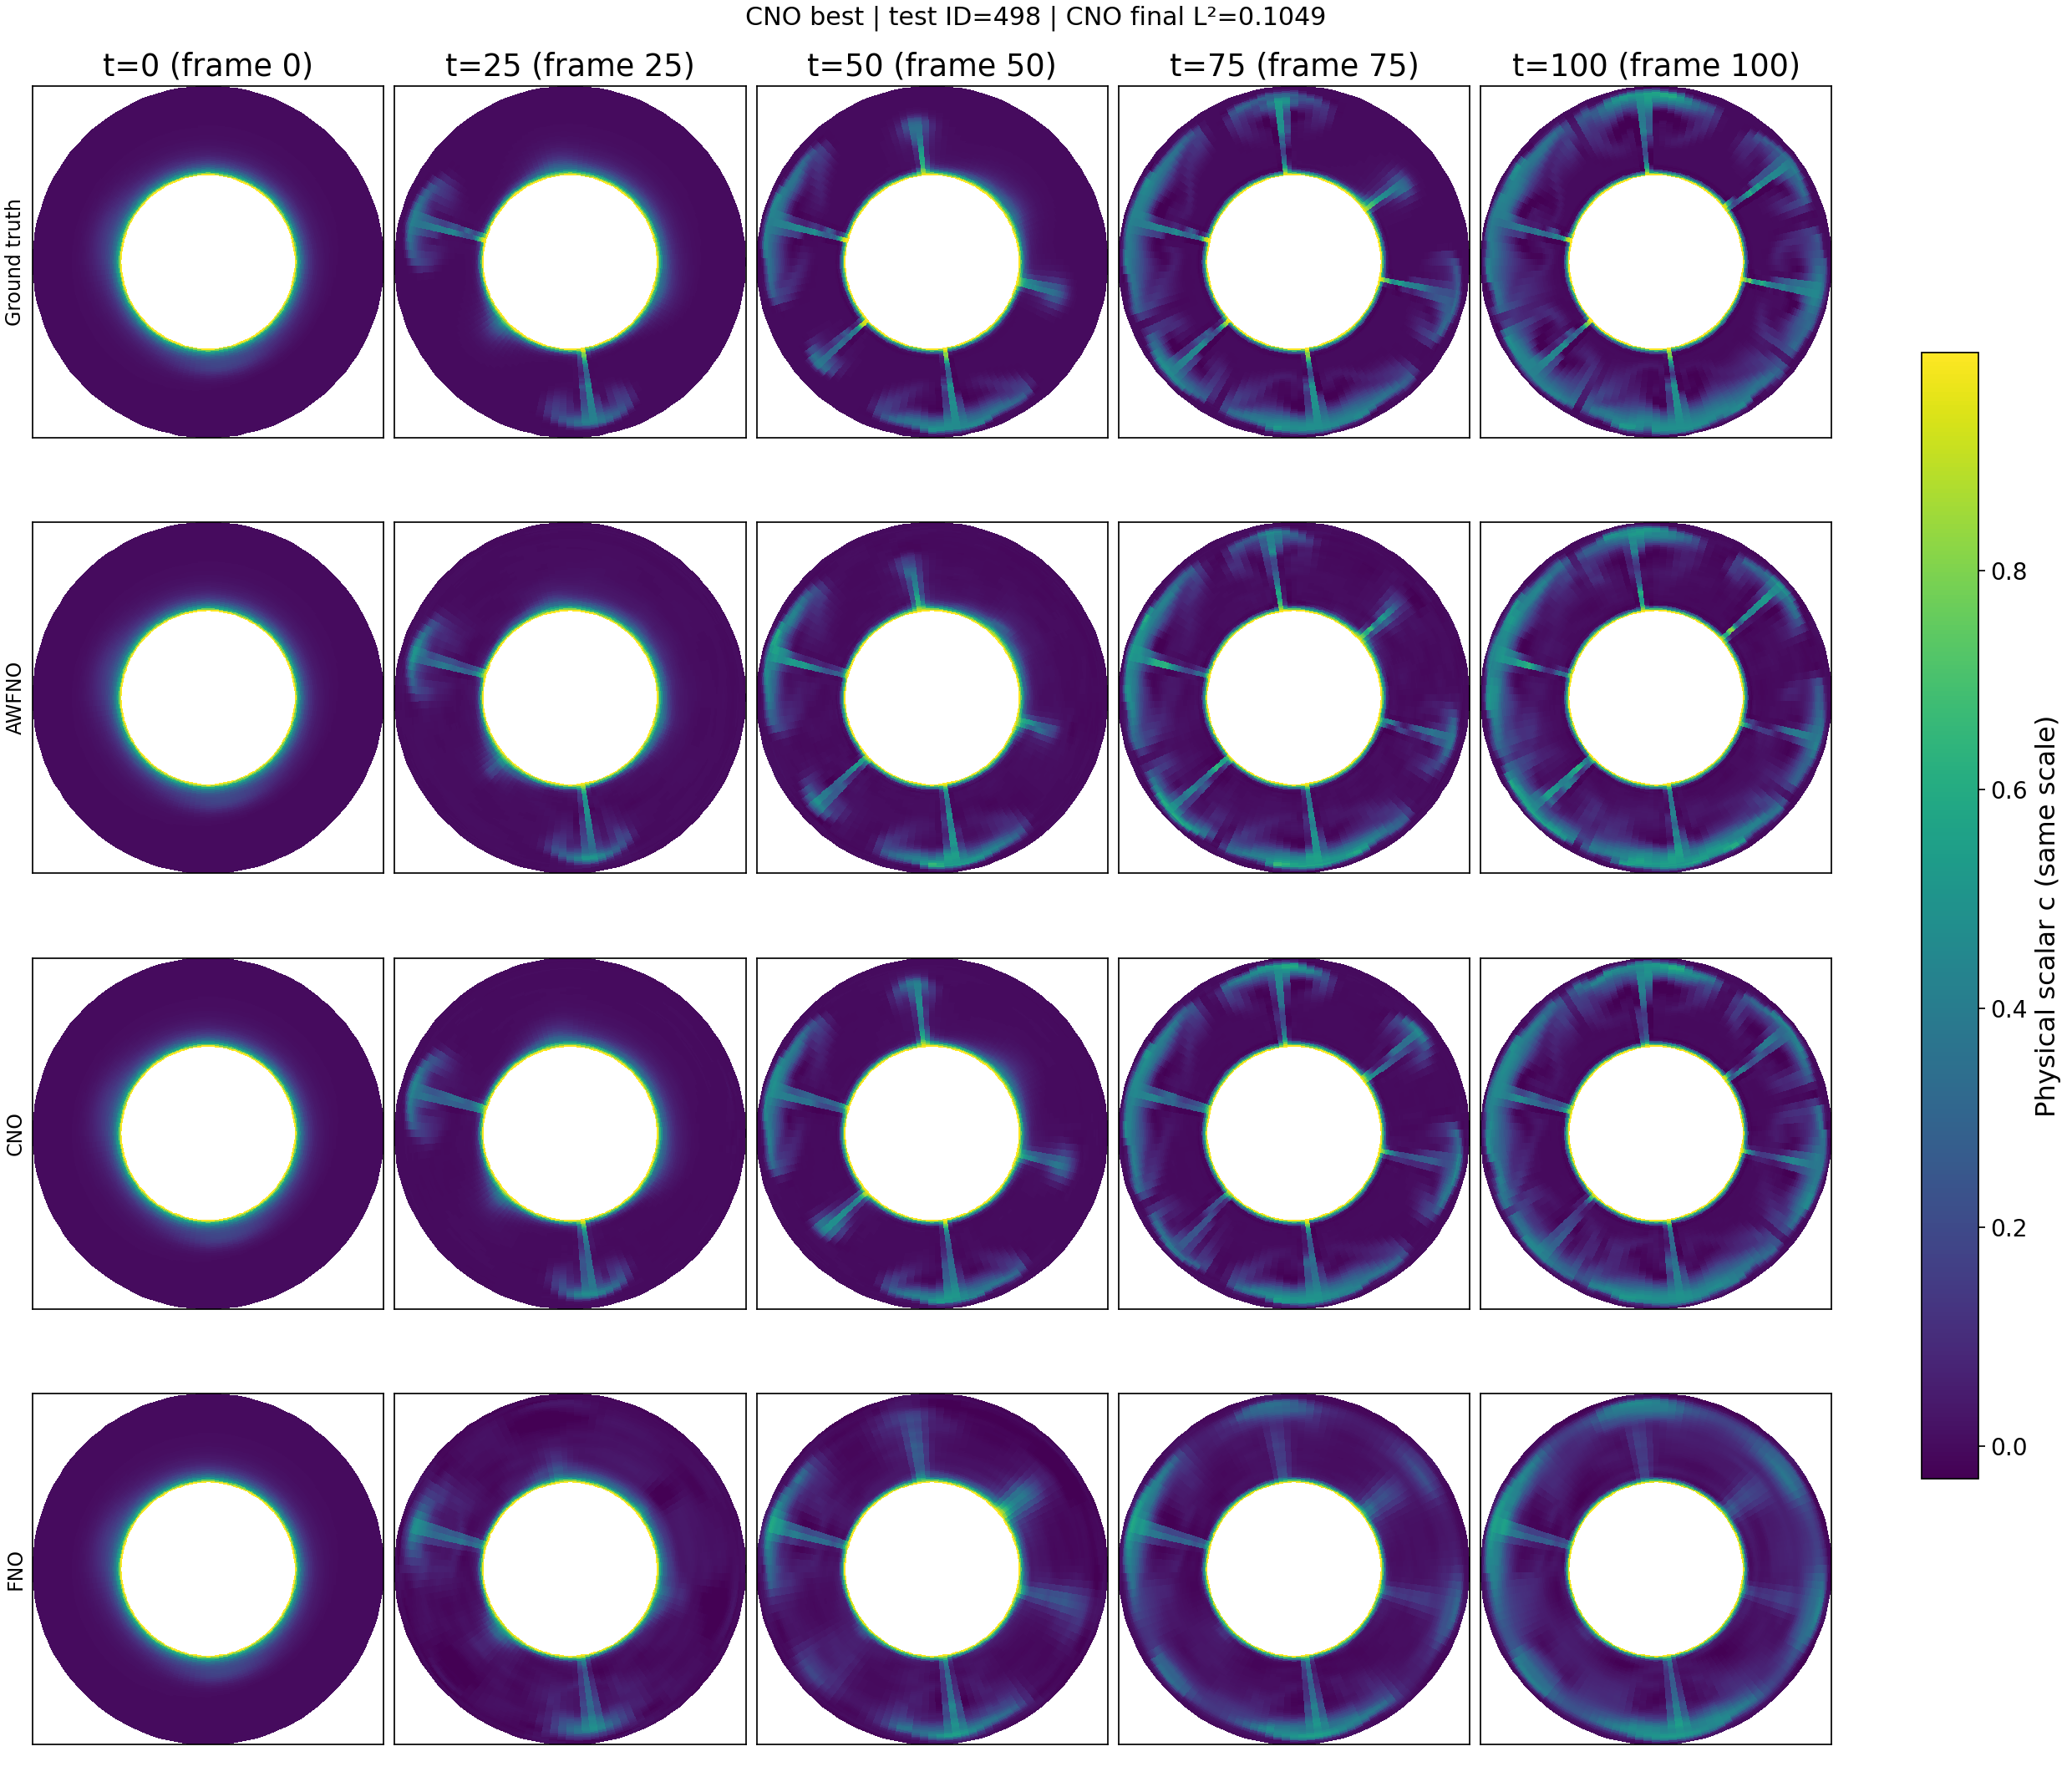

[PLOT] /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200/annulus_errors_CNO_best_id498.png


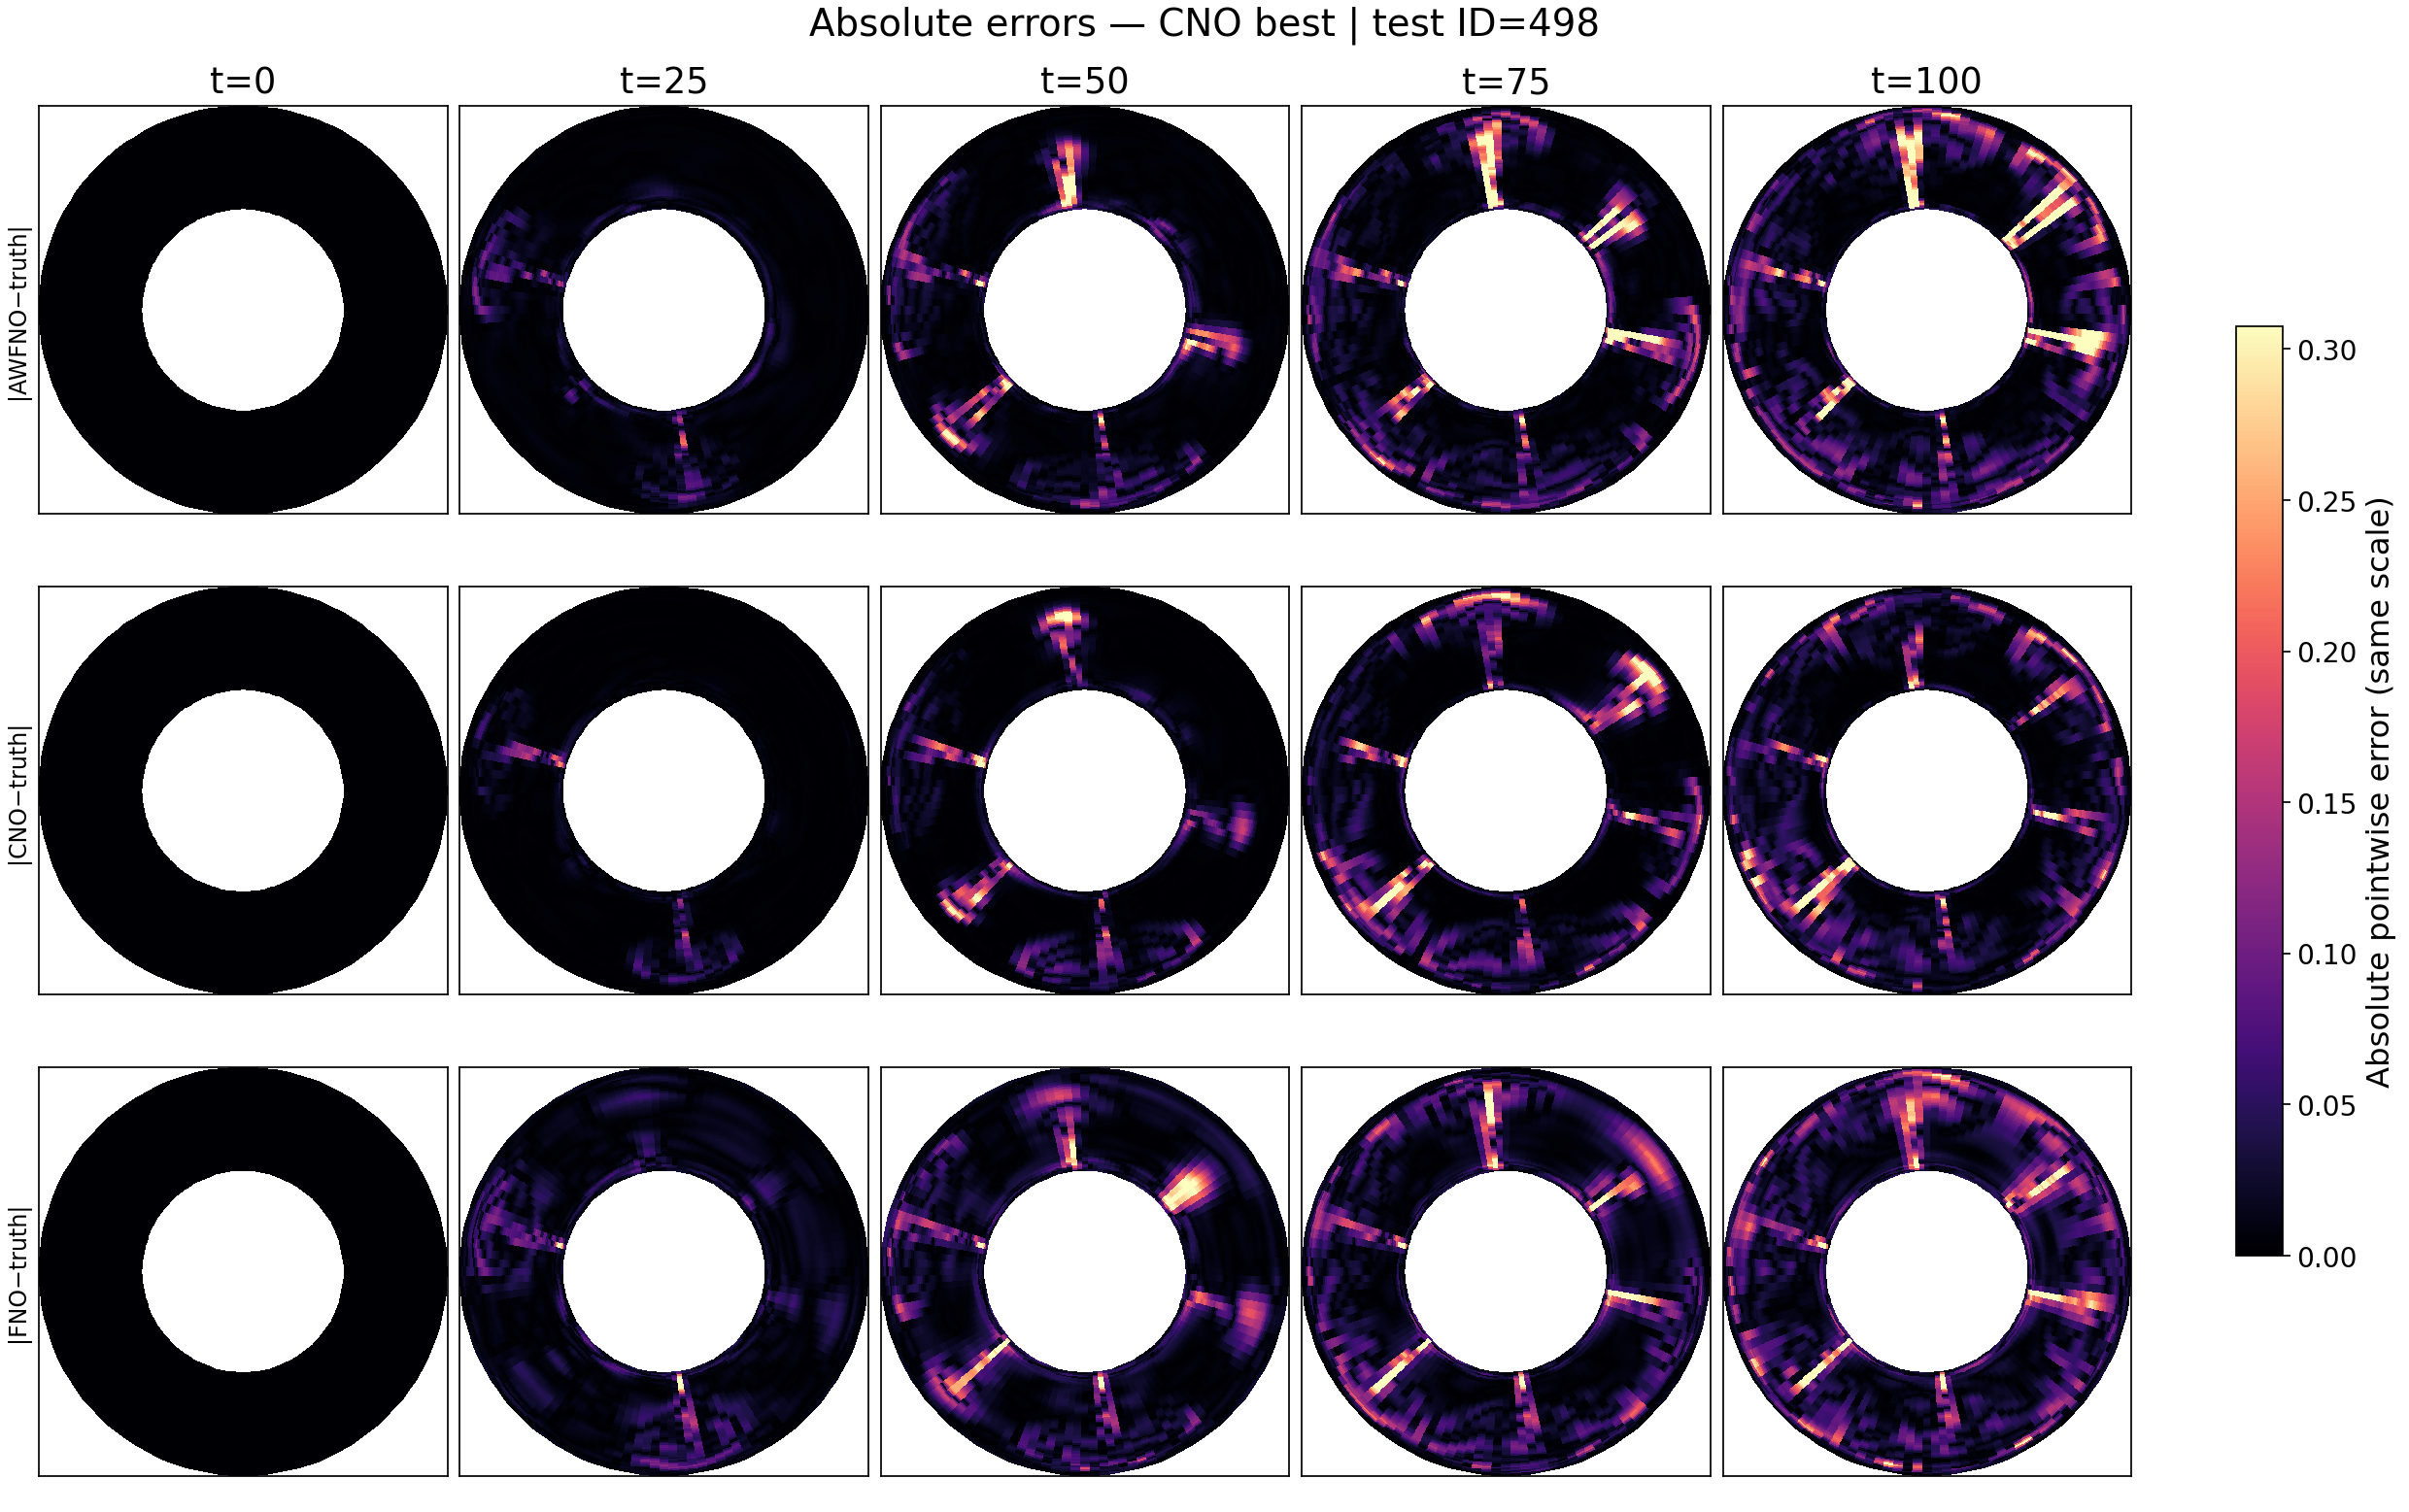

[PLOT] /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200/annulus_fields_CNO_median_id471.png


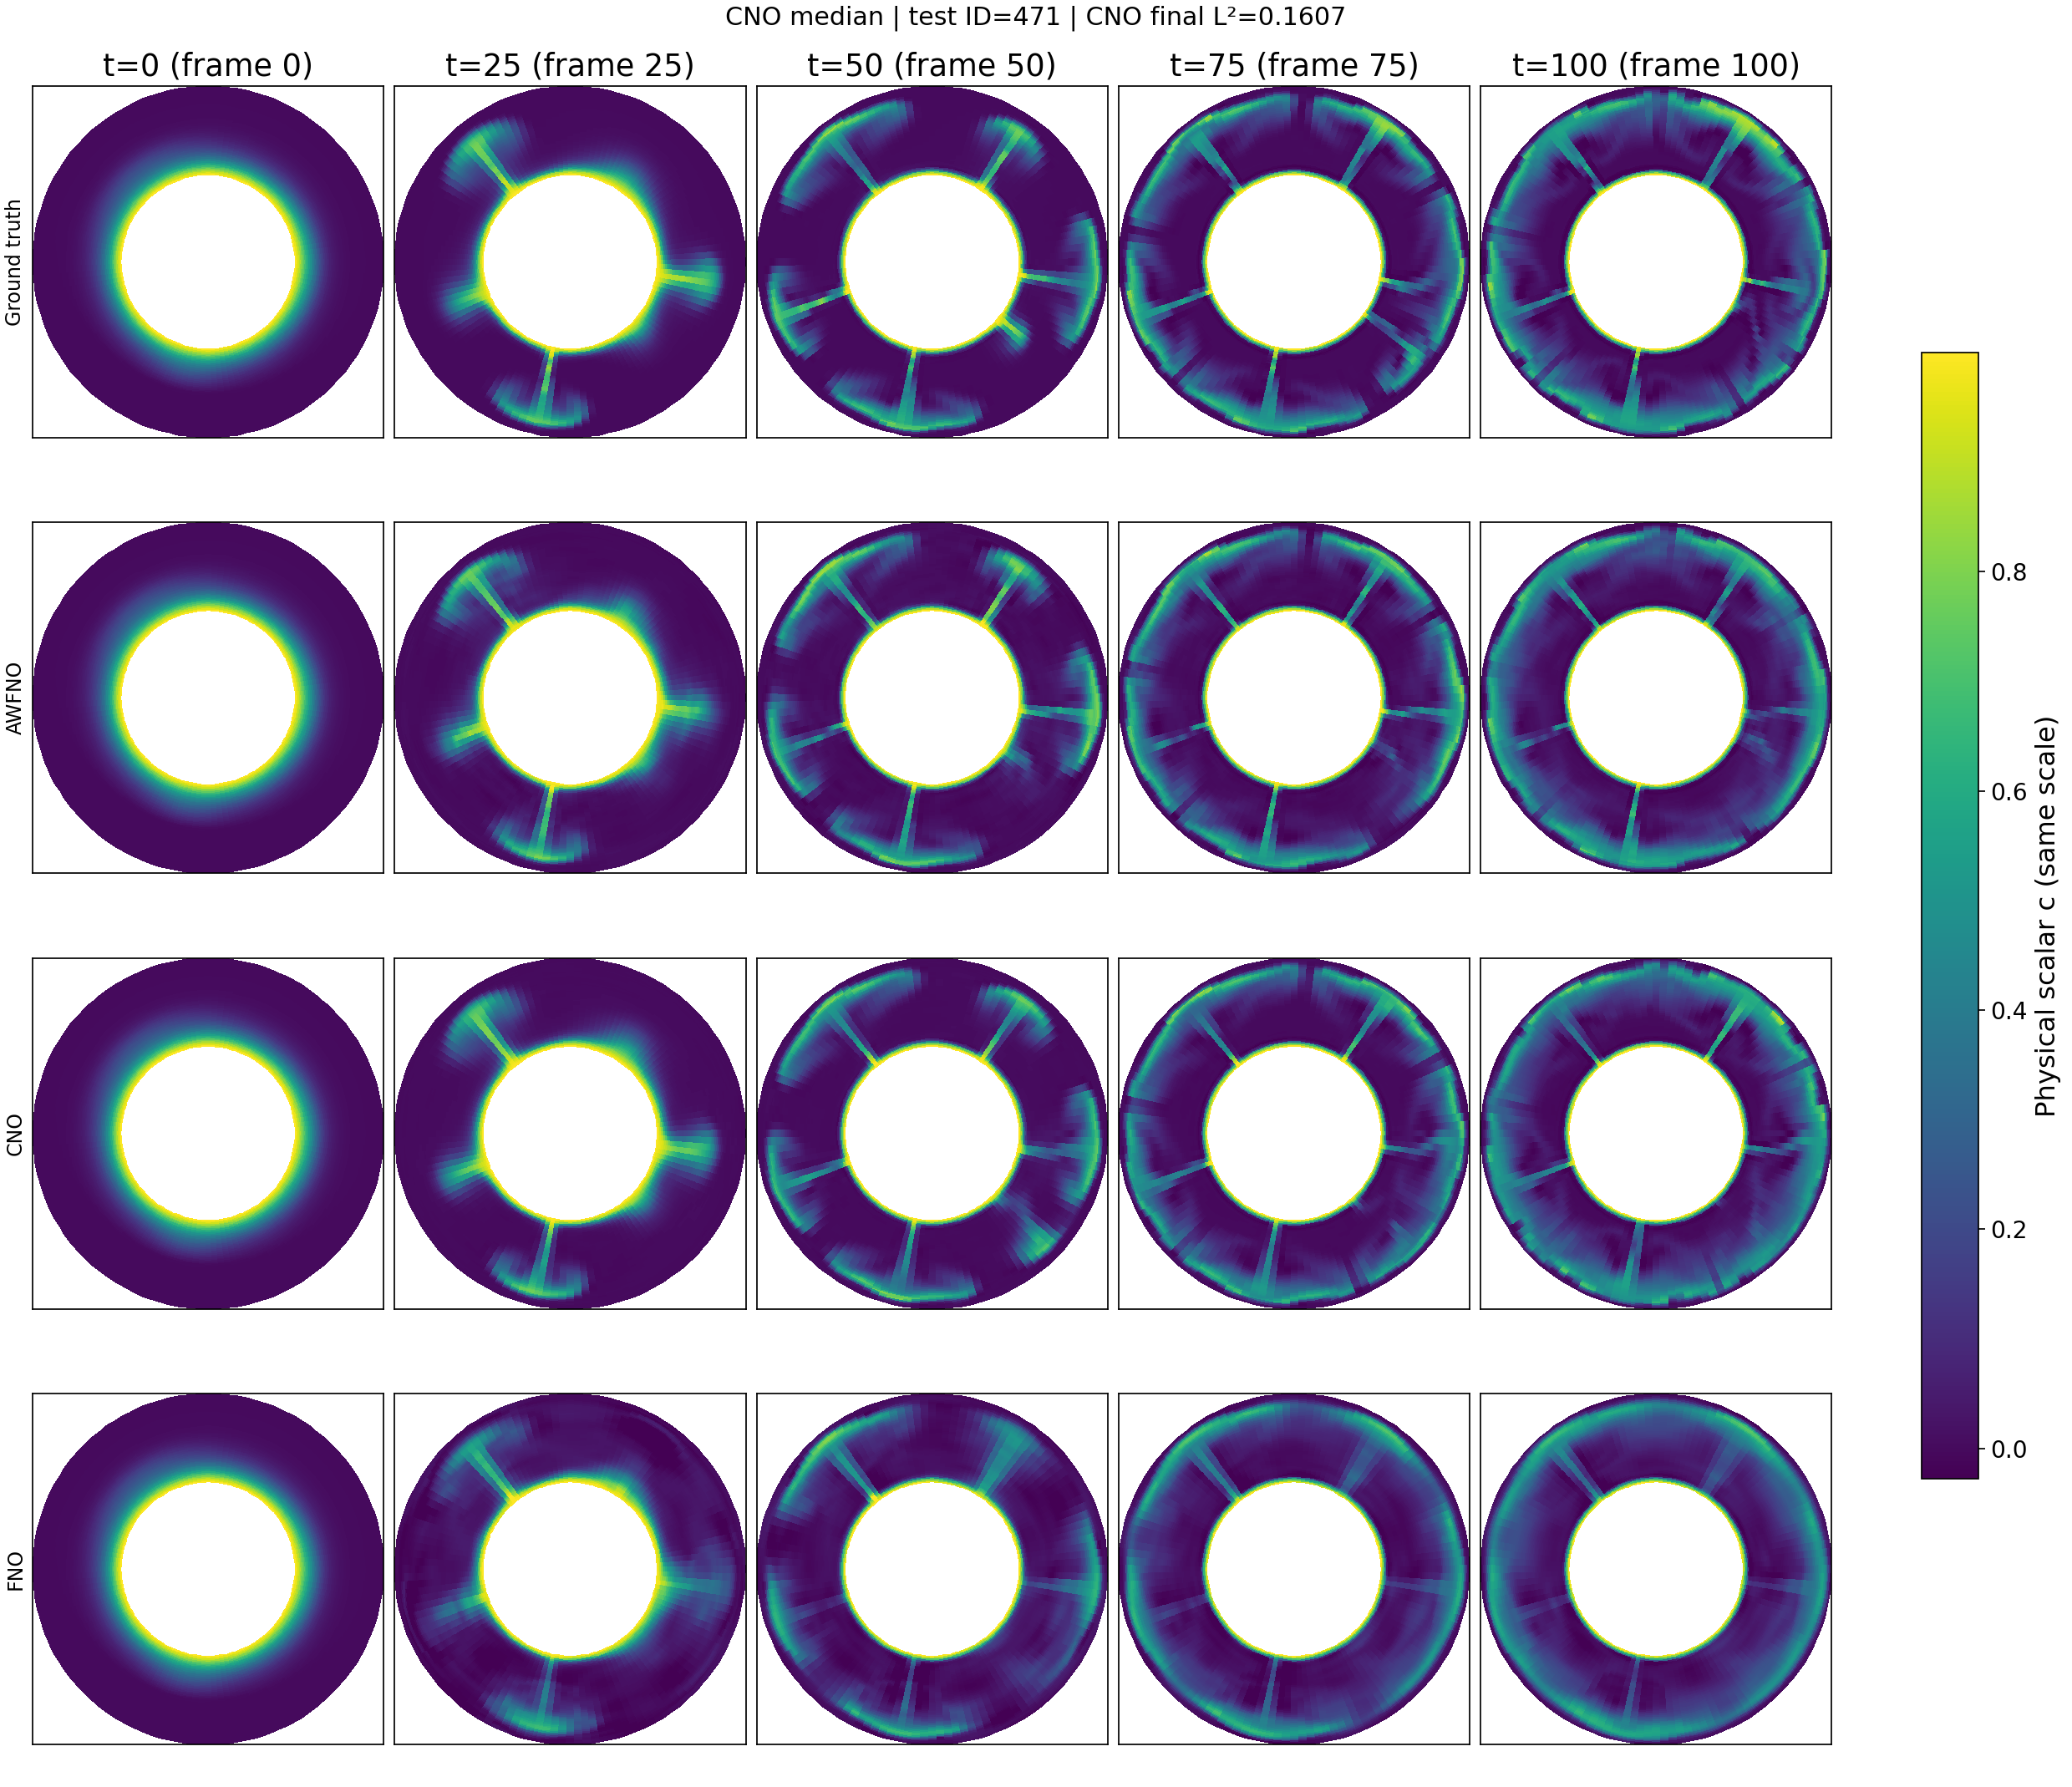

[PLOT] /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200/annulus_errors_CNO_median_id471.png


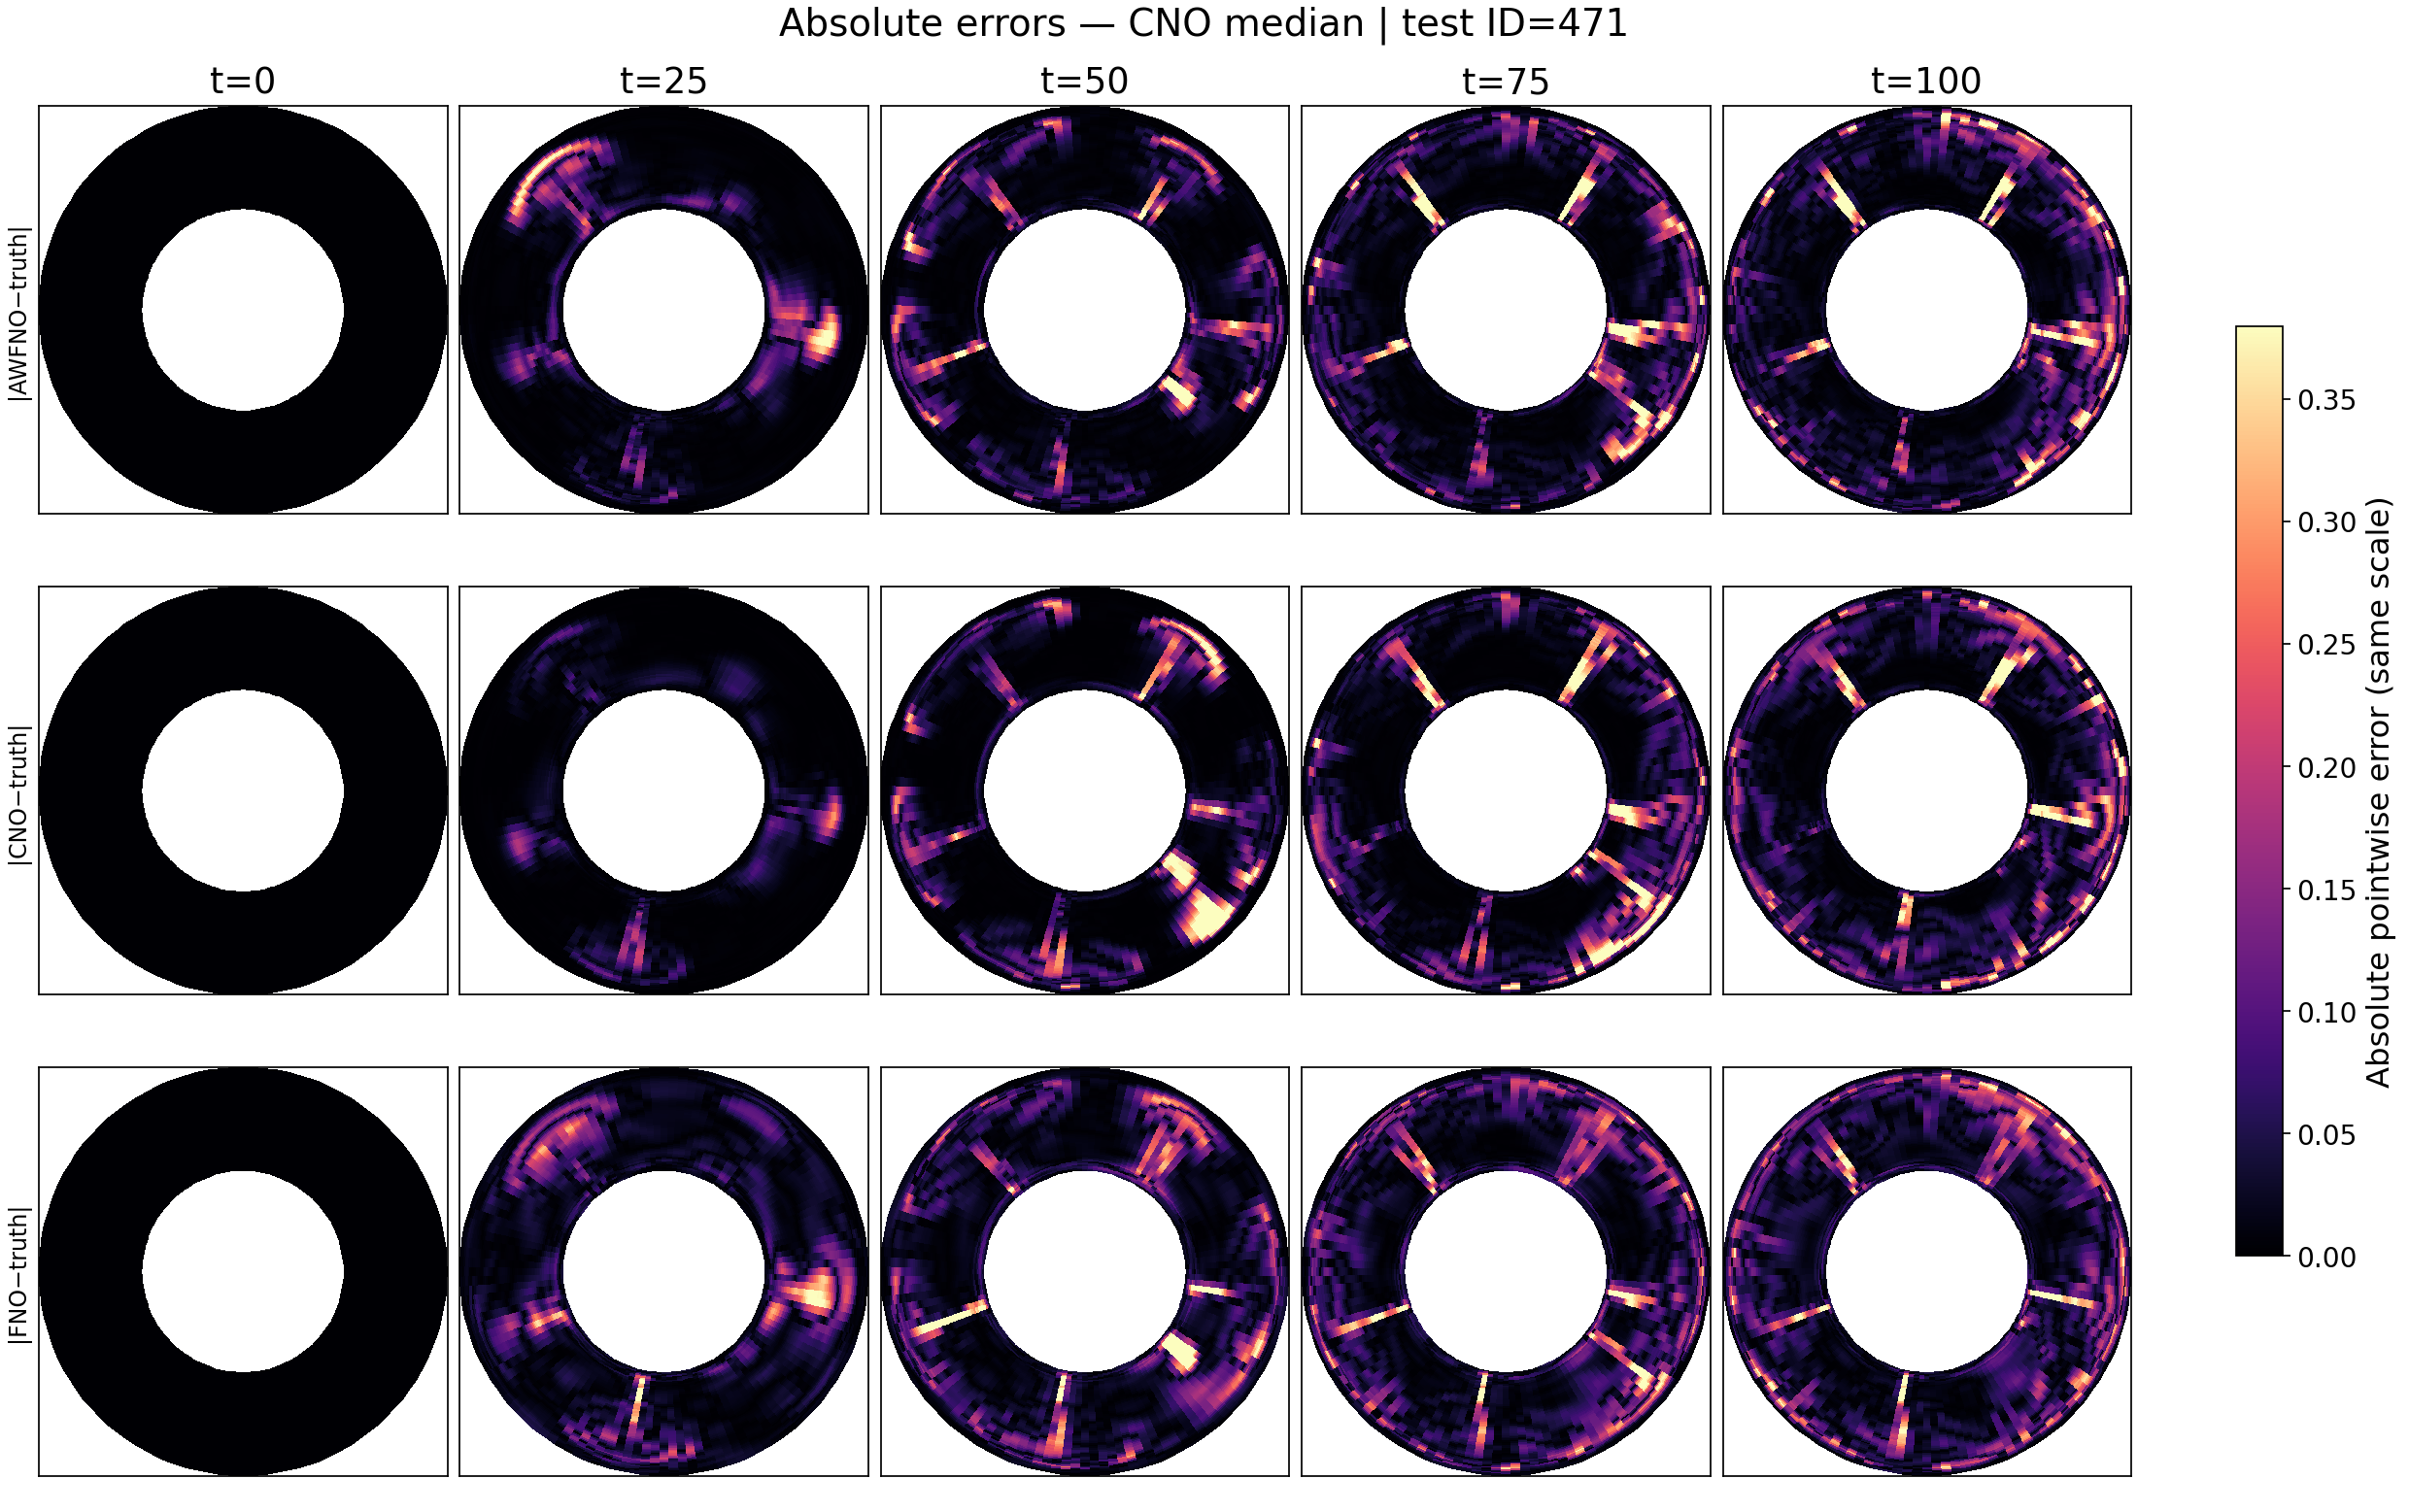

[PLOT] /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200/annulus_fields_CNO_worst_id475.png


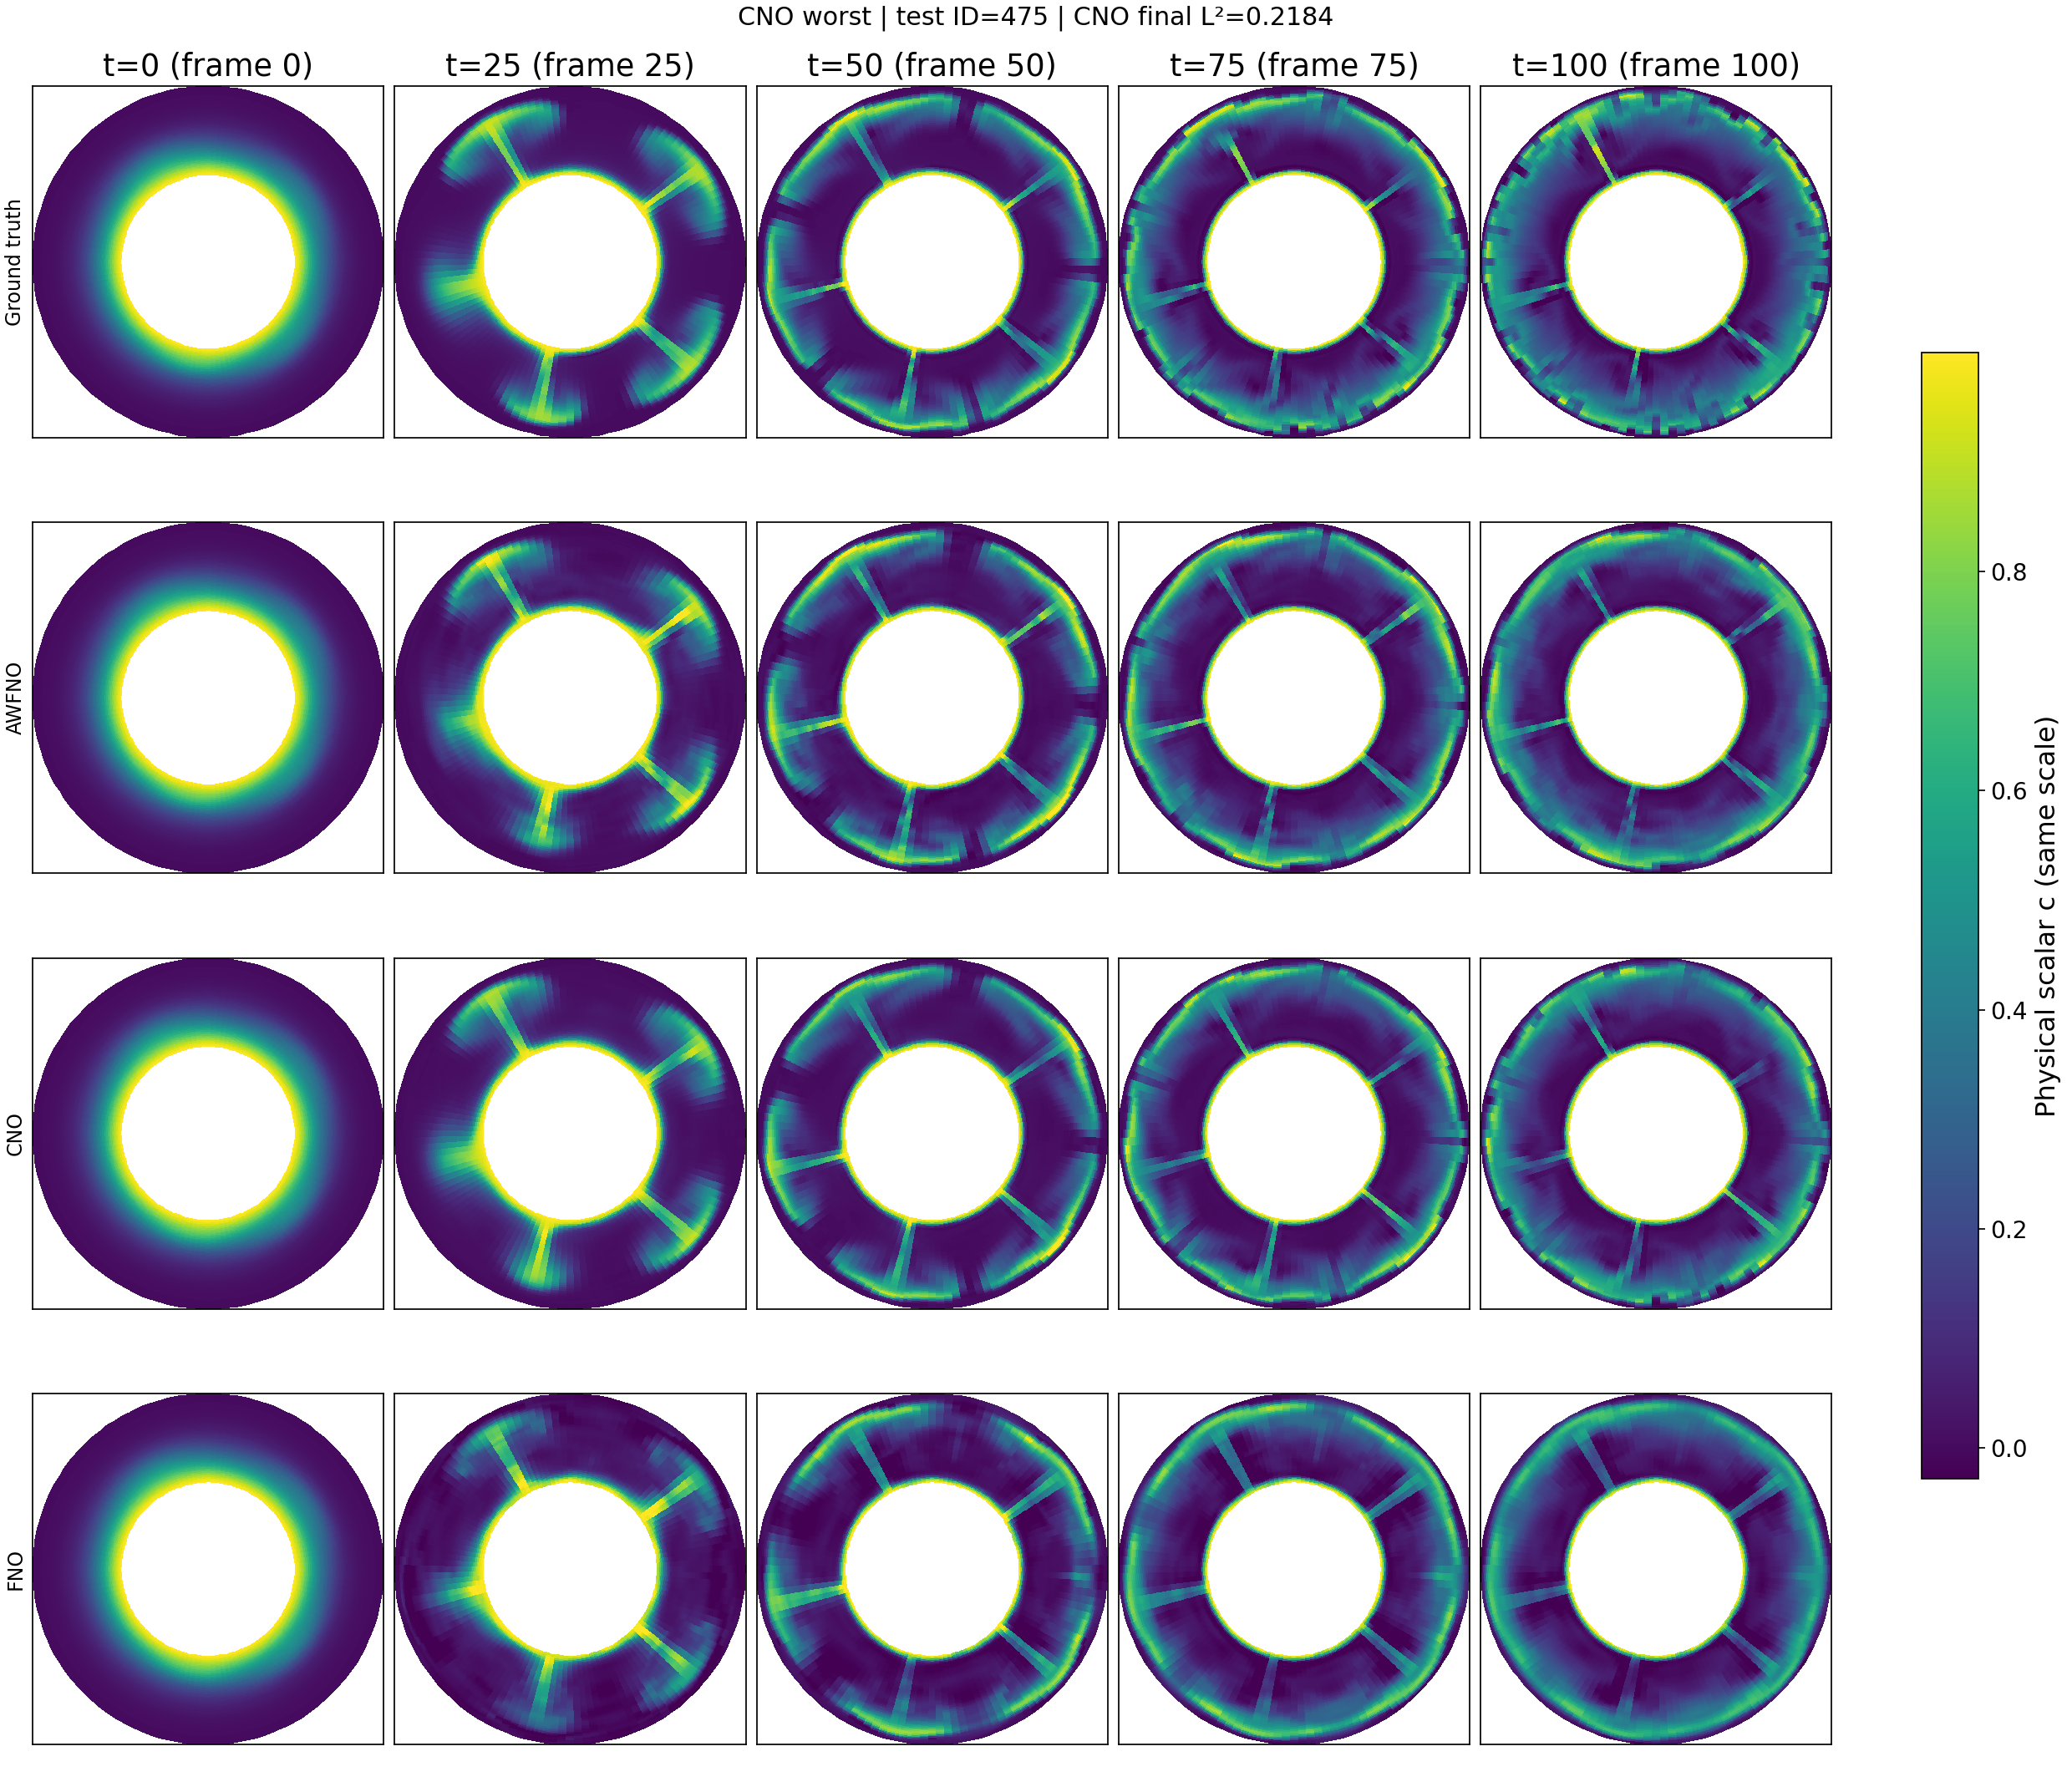

[PLOT] /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200/annulus_errors_CNO_worst_id475.png


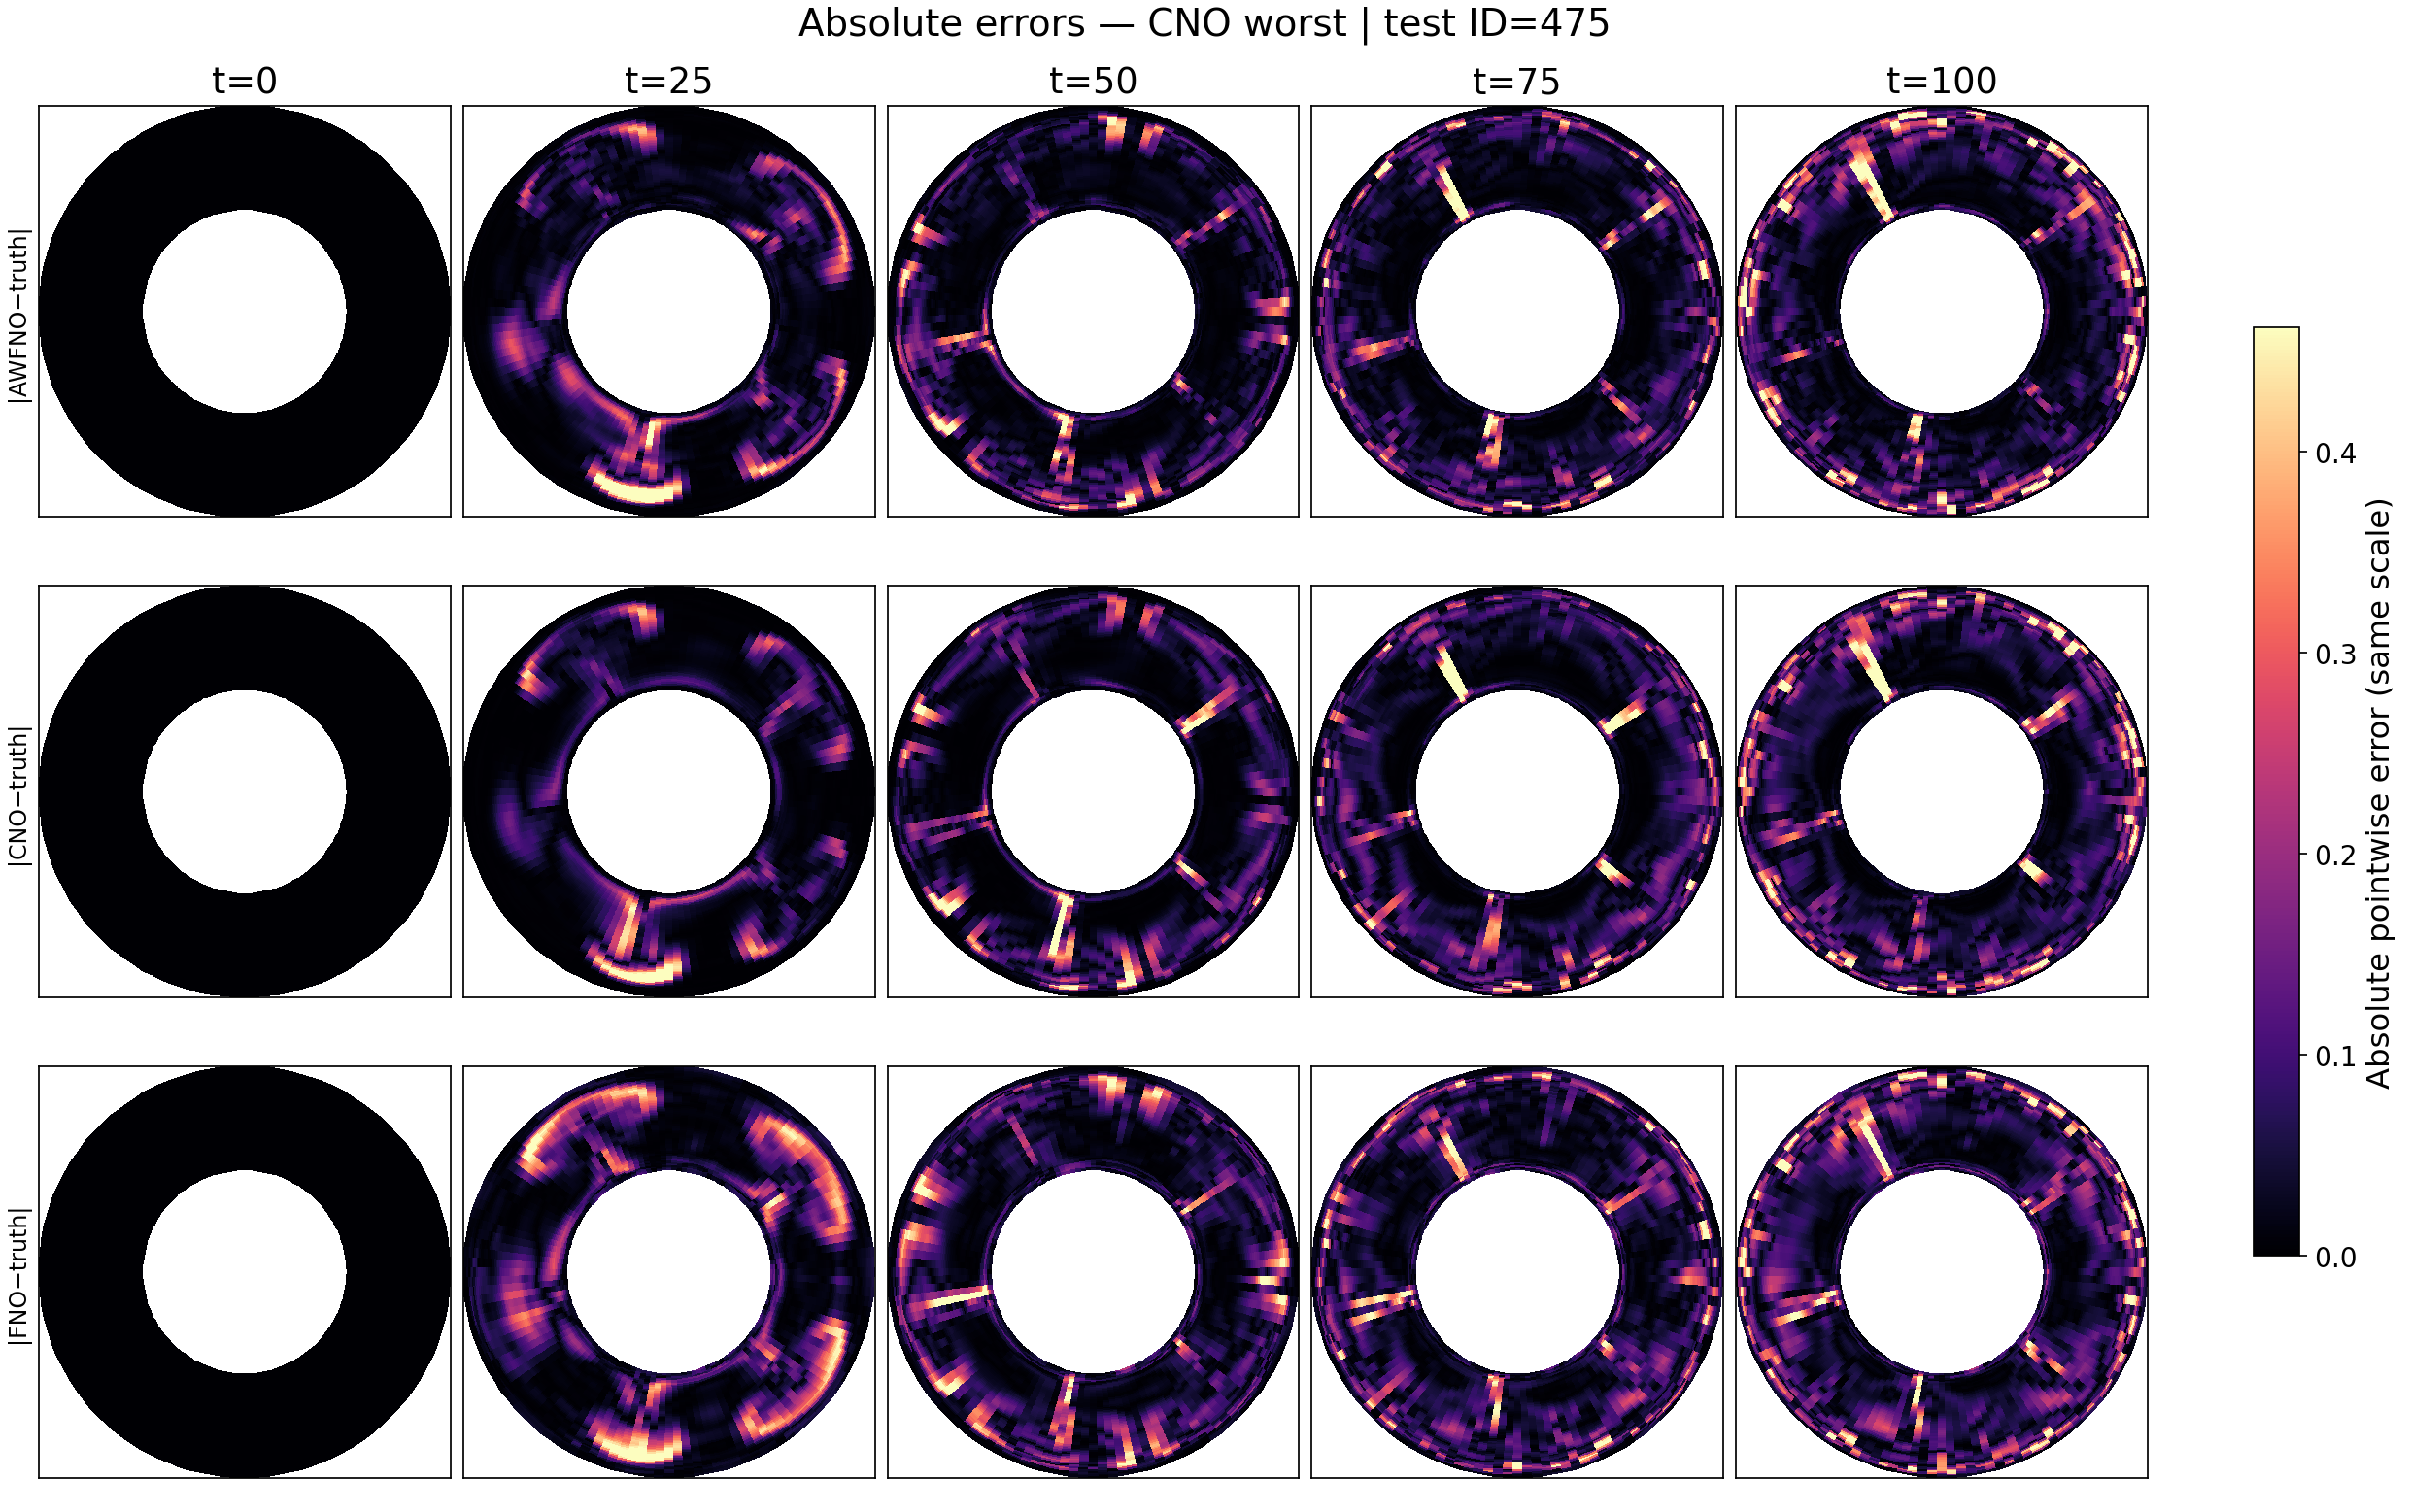

[IMAGES COMPLETE] Ground truth, CNO, AWFNO and optional FNO at same times/scales.


In [6]:
#@title 6. Plot physical ANNULUS truth vs AWFNO vs CNO vs FNO: three ranked test cases
from IPython.display import Image,display
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
# Rank by CNO final *physical* L2 (descriptive test inspection only).
scores=metrics_by_model['CNO']['L2'][:,-1]
order=np.argsort(scores)
cases=[('CNO best',int(order[0])),
       ('CNO median',int(order[len(order)//2])),
       ('CNO worst',int(order[-1]))]
times=[0,25,50,75,100]
theta_closed=np.append(theta.astype(float),float(theta[0])+2*np.pi)
rr_mesh,tt_mesh=np.meshgrid(r,theta_closed,indexing='ij')
X=rr_mesh*np.cos(tt_mesh);Y=rr_mesh*np.sin(tt_mesh)

def show_annulus(ax,z,cmap,norm):
    zz=np.concatenate([z,z[:,:1]],axis=1)
    im=ax.pcolormesh(X,Y,zz,shading='auto',cmap=cmap,norm=norm,
                     rasterized=True)
    ax.set_aspect('equal')
    ax.set_xticks([]);ax.set_yticks([])
    return im
def fields_plot(tag,ix):
    names=['Ground truth','AWFNO','CNO']+(['FNO'] if 'FNO' in preds else [])
    fig,axs=plt.subplots(len(names),len(times),figsize=(16,3.45*len(names)),
                         constrained_layout=True,squeeze=False)
    actual=test[ix]
    low=float(np.quantile(actual,.005));high=float(np.quantile(actual,.995))
    if high-low<1e-8:low=float(actual.min())-1e-4;high=float(actual.max())+1e-4
    true_norm=Normalize(vmin=low,vmax=high)
    im=None
    for i,name in enumerate(names):
        field=actual if name=='Ground truth' else preds[name][ix]
        for j,ti in enumerate(times):
            im=show_annulus(axs[i,j],field[...,ti],'viridis',true_norm)
            if i==0:axs[i,j].set_title(f't={float(t[ti]):.4g} (frame {ti})')
            if j==0:axs[i,j].set_ylabel(name,fontsize=11)
    fig.colorbar(im,ax=axs,shrink=.65,label='Physical scalar c (same scale)')
    fig.suptitle(f'{tag} | test ID={int(test_ids[ix])} | '
                 f'CNO final L²={scores[ix]:.4f}',fontsize=14)
    dest=OUT/f'annulus_fields_{tag.replace(" ","_")}_id{int(test_ids[ix])}.png'
    fig.savefig(dest,dpi=155)
    plt.close(fig)
    print('[PLOT]',dest)
    display(Image(filename=str(dest),width=1000))

    choices=[k for k in names if k!='Ground truth']
    fig,axs=plt.subplots(len(choices),len(times),
                         figsize=(16,3.35*len(choices)),constrained_layout=True,
                         squeeze=False)
    errs=[np.abs(preds[key][ix]-actual) for key in choices]
    errmax=max(float(np.quantile(v,.99)) for v in errs)
    for i,name in enumerate(choices):
        for j,ti in enumerate(times):
            im=show_annulus(axs[i,j],errs[i][...,ti],'magma',
                            Normalize(vmin=0,vmax=max(errmax,1.e-7)))
            if i==0:axs[i,j].set_title(f't={float(t[ti]):.4g}')
            if j==0:axs[i,j].set_ylabel(f'|{name}−truth|',fontsize=11)
    fig.colorbar(im,ax=axs,shrink=.65,label='Absolute pointwise error (same scale)')
    fig.suptitle(f'Absolute errors — {tag} | test ID={int(test_ids[ix])}')
    dest=OUT/f'annulus_errors_{tag.replace(" ","_")}_id{int(test_ids[ix])}.png'
    fig.savefig(dest,dpi=155);plt.close(fig)
    print('[PLOT]',dest)
    display(Image(filename=str(dest),width=1000))

for tag,ix in cases:
    fields_plot(tag,ix)
print('[IMAGES COMPLETE] Ground truth, CNO, AWFNO and optional FNO at same times/scales.')


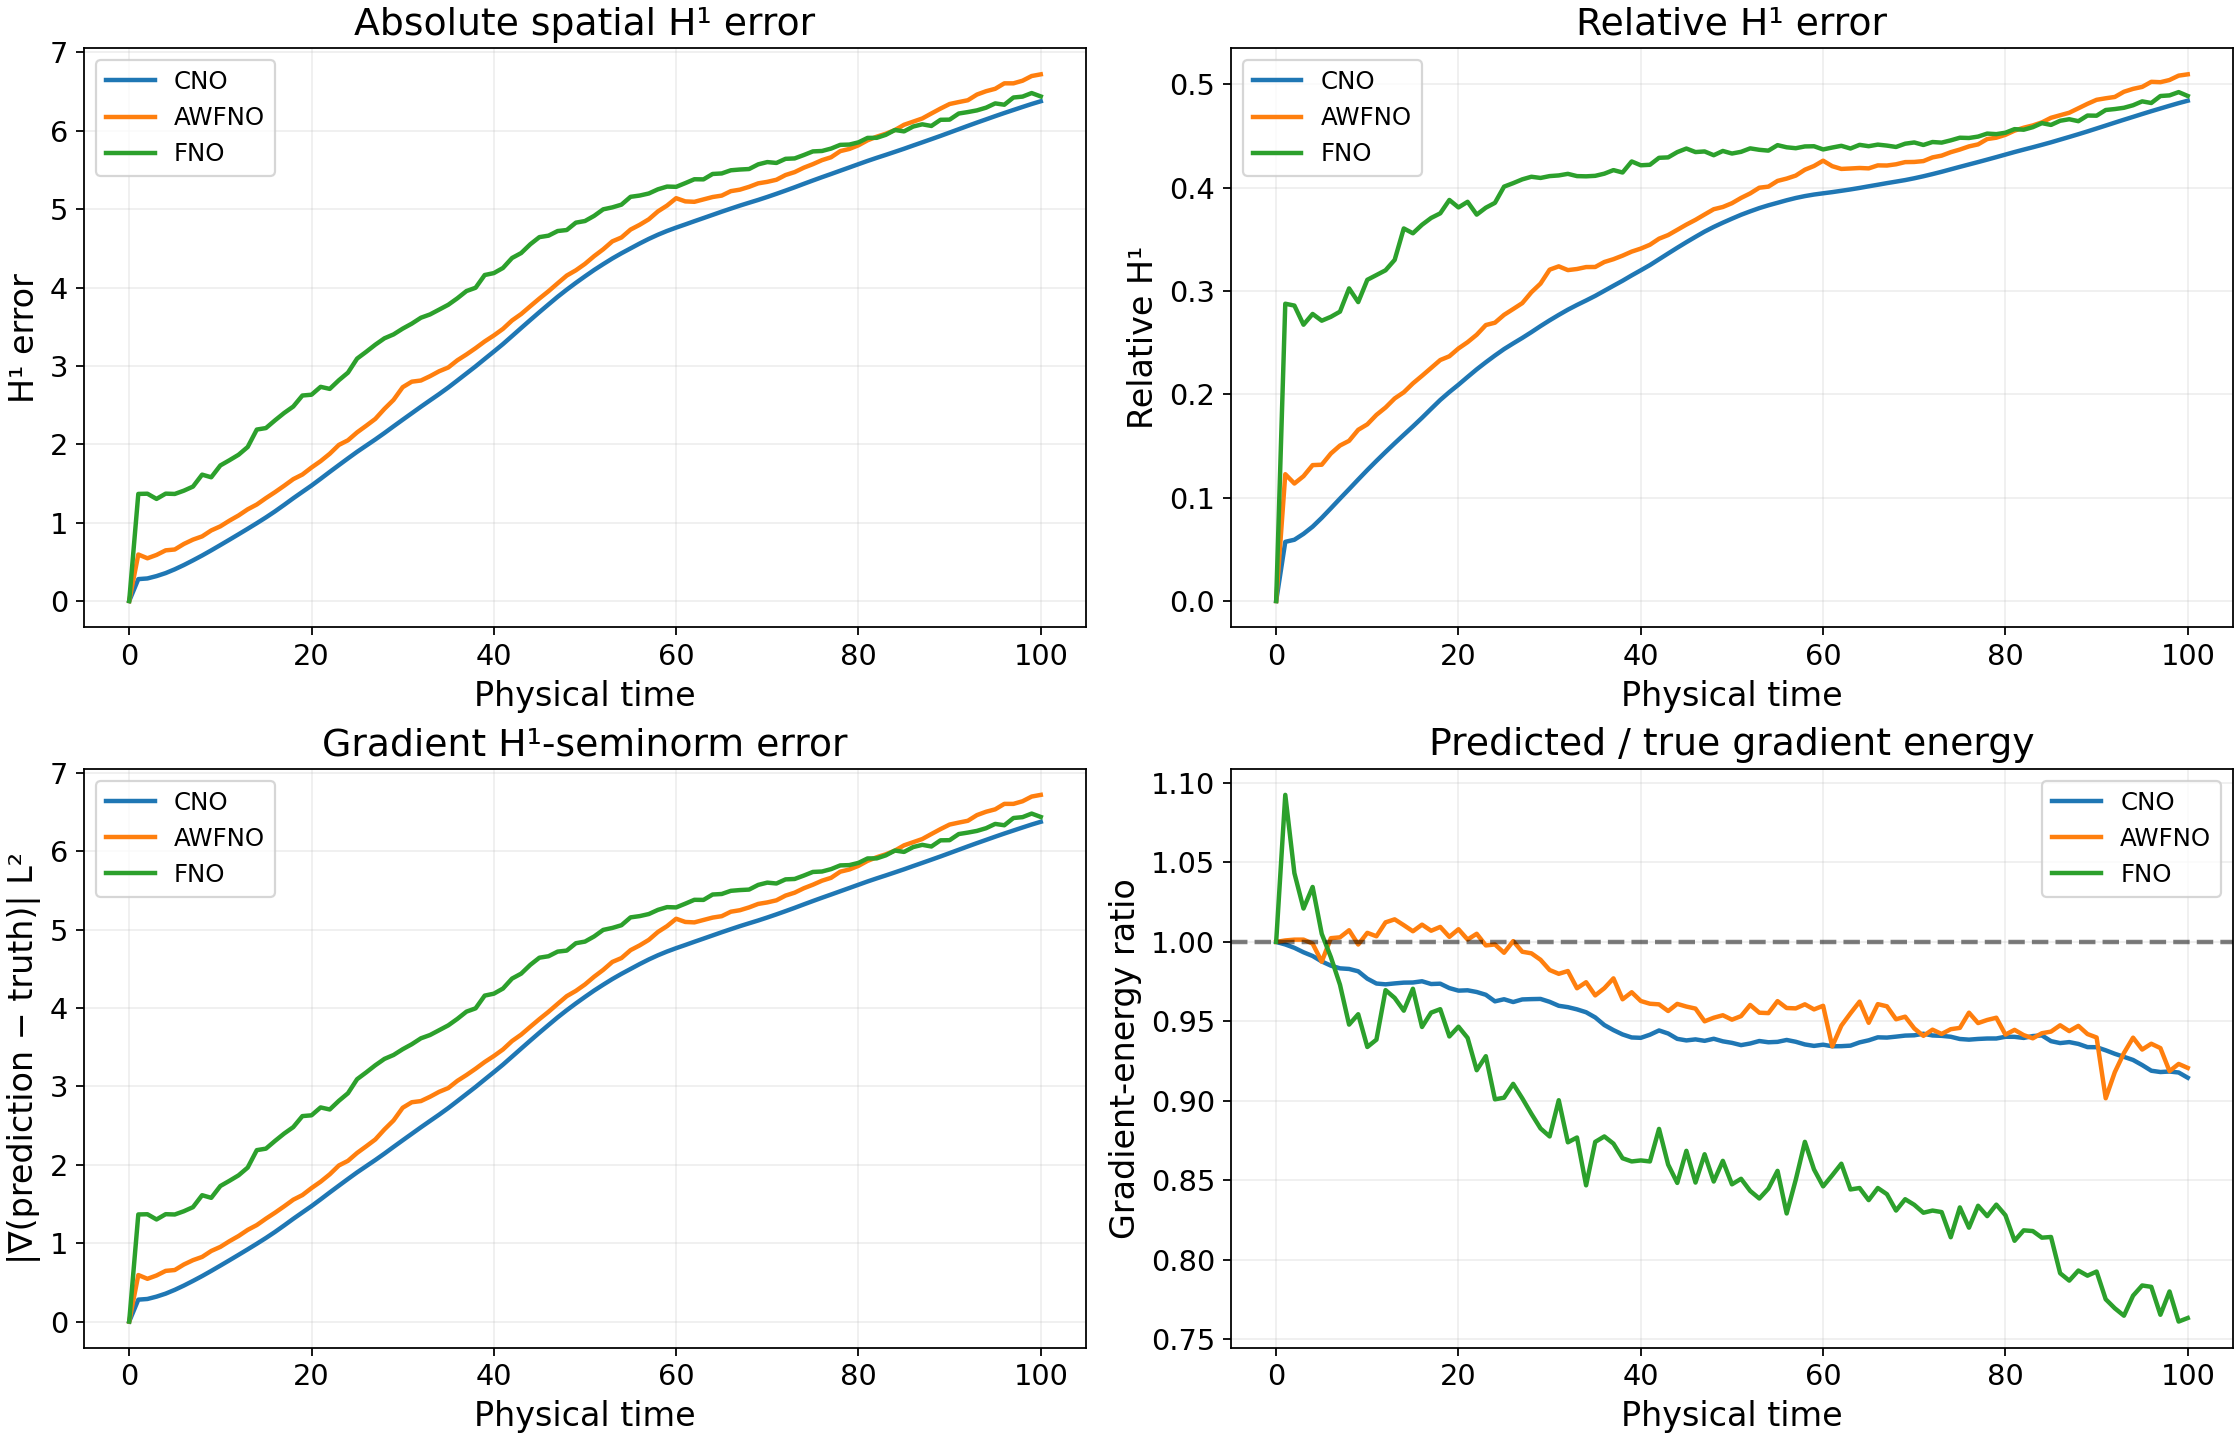

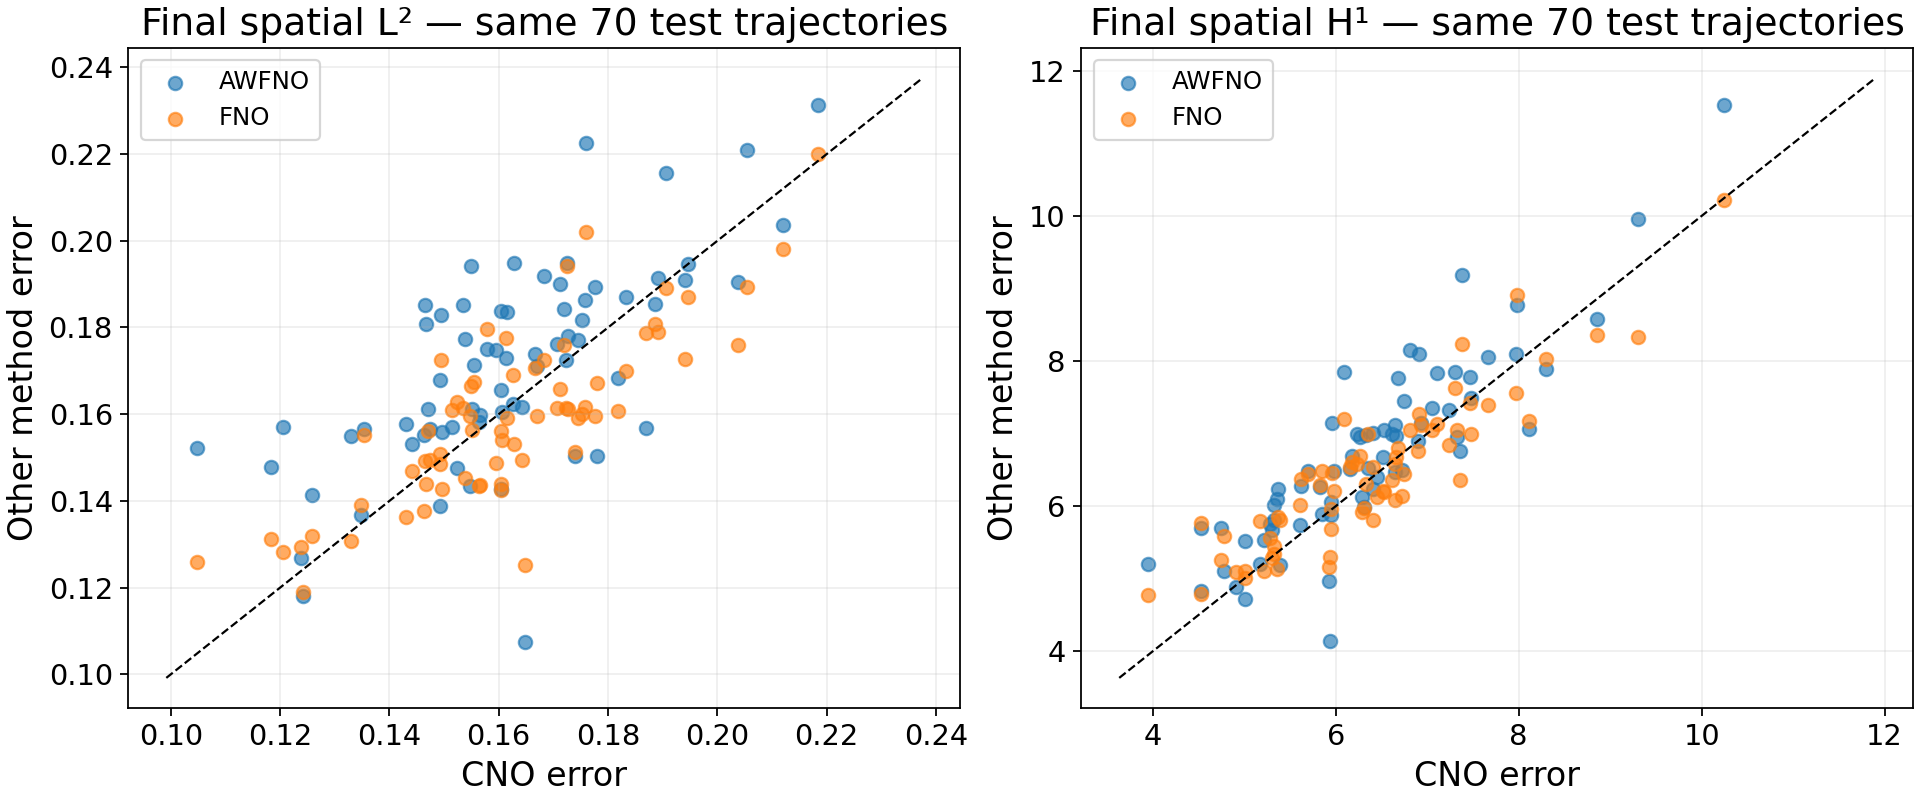

Finished. Existing model checkpoints remain unchanged. Outputs: /content/gdrive/MyDrive/anus/Boussinesq_JCP/CNO_AWFNO_H1_visual_comparison_N200


In [7]:
#@title 7. H¹ vs time, gradient-energy recovery, and paired errors
from matplotlib import pyplot as plt
fig,axs=plt.subplots(2,2,figsize=(14,9),constrained_layout=True)
for name,m in metrics_by_model.items():
    axs[0,0].plot(t,m['H1'].mean(axis=0),label=name)
    axs[0,1].plot(t,m['relative_H1'].mean(axis=0),label=name)
    axs[1,0].plot(t,m['H1_semi'].mean(axis=0),label=name)
    axs[1,1].plot(t,np.median(m['grad_energy_ratio'],axis=0),label=name)
for ax,title,ylabel in [
    (axs[0,0],'Absolute spatial H¹ error','H¹ error'),
    (axs[0,1],'Relative H¹ error','Relative H¹'),
    (axs[1,0],'Gradient H¹-seminorm error','|∇(prediction − truth)| L²'),
    (axs[1,1],'Predicted / true gradient energy','Gradient-energy ratio')]:
    ax.set_title(title);ax.set_xlabel('Physical time');ax.set_ylabel(ylabel)
    ax.grid(alpha=.2);ax.legend()
axs[1,1].axhline(1,color='black',ls='--',alpha=.5)
plot=OUT/'H1_gradients_vs_time.png'
fig.savefig(plot,dpi=160);plt.close(fig);display(Image(filename=str(plot),width=1100))
fig,axs=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for name in preds:
    if name=='CNO':continue
    axs[0].scatter(metrics_by_model['CNO']['L2'][:,-1],
                   metrics_by_model[name]['L2'][:,-1],label=name,alpha=.65)
    axs[1].scatter(metrics_by_model['CNO']['H1'][:,-1],
                   metrics_by_model[name]['H1'][:,-1],label=name,alpha=.65)
for ax,title in zip(axs,['Final spatial L²','Final spatial H¹']):
    mn=min(ax.get_xlim()[0],ax.get_ylim()[0]);mx=max(ax.get_xlim()[1],ax.get_ylim()[1])
    ax.plot([mn,mx],[mn,mx],'k--',lw=1)
    ax.set_xlabel('CNO error');ax.set_ylabel('Other method error')
    ax.set_title(title+' — same 70 test trajectories')
    ax.legend();ax.grid(alpha=.2)
plot=OUT/'paired_CNO_vs_AWFNO_FNO.png'
fig.savefig(plot,dpi=160);plt.close(fig);display(Image(filename=str(plot),width=1100))
print('Finished. Existing model checkpoints remain unchanged. Outputs:',OUT)
